# FFN baseline reproduction

Reproduce the four-class preprocessing and original FFN from `data7703.ipynb` before making model changes.
Source snapshot: `b6e0befd6bc43390af6c5a048108e816dd223bd8`.

Two preprocessing fixes are required: write `Primary_Gene` to `data_ready`, and clean `MC` before dropping it.
The feature rules, label mapping, split, and FFN hyperparameters follow the teammate's notebook.
This run adds a fixed random seed and epoch logging for repeatability. The original FFN did not set a PyTorch seed,
so its exact metrics are not guaranteed. CPU threads are limited to reduce overhead for small batches.

Select the project's `.venv/Scripts/python.exe` interpreter and run all cells in order.


## Portable contribution copy

This independent contribution is stored under `contributions/terrygao03-cell/`.
The executed numerical results are retained; local Windows paths in displayed output have been normalized.
The data location is configurable through `CLINVAR_CSV`. Large generated datasets and row predictions are omitted.
See the local README for full reproduction and explanation-only execution instructions.


## 1. Preview the source data

In [1]:
import pandas as pd

preview = pd.read_csv(
    "clinvar.csv",
    nrows=5,
    dtype={"CHROM": str}
)

print(preview.columns.tolist())
display(preview)

['Unnamed: 0', 'CHROM', 'POS', 'ID', 'REF', 'ALT', 'QUAL', 'FILTER', 'INFO', 'CLNSIG', 'Varyant_Tipi', 'Target', 'CHROM_Encoded', 'VT_Encoded']


,Unnamed: 0,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,CLNSIG,Varyant_Tipi,Target,CHROM_Encoded,VT_Encoded
0,1,1,69134,2205837,A,G,.,.,ALLELEID=2193183;CLNDISDB=MedGen:CN169374;CLND...,Likely_benign,SO:0001583|missense_variant,0,0,269
1,21,1,744664,3892489,T,TGGTCAATCA,.,.,"ALLELEID=4008375;CLNDISDB=MONDO:MONDO:0100428,...",Benign,UNKNOWN,0,0,547
2,27,1,859898,3388928,G,C,.,.,ALLELEID=3548054;CLNDISDB=MedGen:C3661900;CLND...,Likely_benign,SO:0001819|synonymous_variant,0,0,525
3,30,1,861336,1543320,C,T,.,.,ALLELEID=1632777;CLNDISDB=MedGen:C3661900;CLND...,Likely_benign,SO:0001819|synonymous_variant,0,0,525
4,32,1,861349,1648427,C,T,.,.,AF_EXAC=0.00033;ALLELEID=1600580;CLNDISDB=MedG...,Likely_benign,SO:0001583|missense_variant,0,0,269


## 2. Load the full dataset and remove old encodings

In [2]:
from pathlib import Path
import os
import json
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from IPython.display import display

CONTRIBUTION_DIR = Path.cwd()
if not (CONTRIBUTION_DIR / "ffn_baseline.ipynb").is_file():
    CONTRIBUTION_DIR = CONTRIBUTION_DIR / "contributions" / "terrygao03-cell"
if not (CONTRIBUTION_DIR / "ffn_baseline.ipynb").is_file():
    raise FileNotFoundError("Run from the repository root or the contribution directory.")
CONTRIBUTION_DIR = CONTRIBUTION_DIR.resolve()
REPO_ROOT = CONTRIBUTION_DIR.parents[1]
RAW_PATH = Path(os.environ.get("CLINVAR_CSV", str(REPO_ROOT / "clinvar.csv"))).expanduser()
OUTPUT_DIR = CONTRIBUTION_DIR / "baseline_results"
print("Raw file:", RAW_PATH)
print("Output directory:", OUTPUT_DIR)


Raw file: .\clinvar.csv
Output directory: .\baseline_results


In [3]:
data = pd.read_csv(RAW_PATH, dtype={"CHROM": str})
pre_encoded_cols = ["Target", "CHROM_Encoded", "VT_Encoded", "Unnamed: 0"]
data = data.drop(columns=[col for col in pre_encoded_cols if col in data.columns])
required = {"CHROM", "POS", "REF", "ALT", "INFO", "CLNSIG"}
if not required.issubset(data.columns):
    raise ValueError(f"Missing required columns:{required - set(data.columns)}")
print("Loaded shape:", data.shape)
display(data.head(3))


Loaded shape: (1686794, 10)


,CHROM,POS,ID,REF,ALT,QUAL,FILTER,INFO,CLNSIG,Varyant_Tipi
0,1,69134,2205837,A,G,.,.,ALLELEID=2193183;CLNDISDB=MedGen:CN169374;CLND...,Likely_benign,SO:0001583|missense_variant
1,1,744664,3892489,T,TGGTCAATCA,.,.,"ALLELEID=4008375;CLNDISDB=MONDO:MONDO:0100428,...",Benign,UNKNOWN
2,1,859898,3388928,G,C,.,.,ALLELEID=3548054;CLNDISDB=MedGen:C3661900;CLND...,Likely_benign,SO:0001819|synonymous_variant


## 3. Extract INFO fields

Keep variant type, gene information, molecular consequence, and three allele frequencies.
As in the original code, missing or invalid individual frequency values become zero.
This is a baseline convention; missing frequency is not necessarily a measured zero.


In [4]:
target_keys = ["CLNVC", "CLNVCSO", "GENEINFO", "MC", "AF_EXAC", "AF_TGP", "AF_ESP"]

def extract_all_specified_info(info_str):
    if pd.isna(info_str):
        return {key: None for key in target_keys}
    info_dict = {}
    for pair in info_str.split(";"):
        if "=" in pair:
            key, value = pair.split("=", 1)
            info_dict[key] = value
    result = {}
    for key in target_keys:
        val = info_dict.get(key, None)
        if key in ["AF_EXAC", "AF_TGP", "AF_ESP"]:
            try:
                result[key] = float(val) if val is not None else 0.0
            except ValueError:
                result[key] = 0.0
        else:
            result[key] = val
    return result

extracted_features = pd.DataFrame(data["INFO"].apply(extract_all_specified_info).tolist())
data_cleaned = pd.concat([data.reset_index(drop=True), extracted_features.reset_index(drop=True)], axis=1)
cols_to_drop = ["INFO", "CLNVCSO", "Varyant_Tipi", "ID", "QUAL", "FILTER"]
data_ready = data_cleaned.drop(columns=[col for col in cols_to_drop if col in data_cleaned.columns])
print("Shape after INFO extraction:", data_cleaned.shape)


Shape after INFO extraction: (1686794, 17)


## 4. Clean gene names and molecular consequences

Use the first gene symbol and the first consequence description. Fill missing text with `Unknown`.
Create the cleaned features before dropping `GENEINFO` and `MC`.


In [5]:
def clean_geneinfo(gene_str):
    if pd.isna(gene_str):
        return "Unknown"
    first_entry = gene_str.split("|")[0]
    return first_entry.split(":")[0]

def clean_mc(mc_str):
    if pd.isna(mc_str) or mc_str == "None":
        return "Unknown"
    first_part = str(mc_str).split(",")[0]
    return first_part.split("|", 1)[1] if "|" in first_part else first_part

data_ready["Primary_Gene"] = data_ready["GENEINFO"].apply(clean_geneinfo)
data_ready["MC_Clean"] = data_ready["MC"].apply(clean_mc)
data_ready = data_ready.drop(columns=["MC", "GENEINFO"])
print("Any commas remaining in MC_Clean:", data_ready["MC_Clean"].str.contains(",", regex=False).any())
display(data_ready.head(3))


Any commas remaining in MC_Clean: False


,CHROM,POS,REF,ALT,CLNSIG,CLNVC,AF_EXAC,AF_TGP,AF_ESP,Primary_Gene,MC_Clean
0,1,69134,A,G,Likely_benign,single_nucleotide_variant,0.0,0.0,0.0,OR4F5,missense_variant
1,1,744664,T,TGGTCAATCA,Benign,Insertion,0.0,0.0,0.0,LINC01409,Unknown
2,1,859898,G,C,Likely_benign,single_nucleotide_variant,0.0,0.0,0.0,SAMD11,synonymous_variant


## 5. Rebuild the four-class target

Merge `Benign/Likely_benign` into `Likely_benign`, and `Pathogenic/Likely_pathogenic` into `Likely_pathogenic`.
The numeric target order is Benign=0, Likely_benign=1, Likely_pathogenic=2, Pathogenic=3.
Stop on unexpected labels rather than silently filtering rows.


In [6]:
clnsig_4way_mapping = {
    "Benign": "Benign",
    "Benign/Likely_benign": "Likely_benign",
    "Likely_benign": "Likely_benign",
    "Pathogenic": "Pathogenic",
    "Pathogenic/Likely_pathogenic": "Likely_pathogenic",
    "Likely_pathogenic": "Likely_pathogenic",
}
data_ready["Clinical_Significance"] = data_ready["CLNSIG"].map(clnsig_4way_mapping)
if data_ready["Clinical_Significance"].isna().any():
    raise ValueError("Unexpected or missing CLNSIG labels:" + str(data_ready["CLNSIG"].value_counts(dropna=False)))
target_mapping = {"Benign": 0, "Likely_benign": 1, "Likely_pathogenic": 2, "Pathogenic": 3}
data_ready["Target"] = data_ready["Clinical_Significance"].map(target_mapping)
print("Cleaned shape:", data_ready.shape)
print(data_ready["Clinical_Significance"].value_counts())
print("\nMissing values by column:")
print(data_ready.isna().sum())


Cleaned shape: (1686794, 13)
Clinical_Significance
Likely_benign        1144932
Benign                209662
Pathogenic            185024
Likely_pathogenic     147176
Name: count, dtype: int64

Missing values by column:


CHROM                    0
POS                      0
REF                      0
ALT                      0
CLNSIG                   0
CLNVC                    0
AF_EXAC                  0
AF_TGP                   0
AF_ESP                   0
Primary_Gene             0
MC_Clean                 0
Clinical_Significance    0
Target                   0
dtype: int64


## 6. Encode the same eight input features

One-hot encode CHROM, CLNVC, and MC_Clean with `drop_first=True`. Replace Primary_Gene with its occurrence count.
Exclude the target and all clinical-significance labels from model inputs.

For reproduction, encoding and gene counts use the full dataset before splitting, as in the original notebook.
Gene frequencies therefore use test-distribution information. A train-only encoding workflow would be a separate preprocessing change.
No feature scaling, resampling, class weights, or duplicate removal is added here.


In [7]:
features = ["CHROM", "POS", "AF_EXAC", "AF_TGP", "AF_ESP", "CLNVC", "MC_Clean", "Primary_Gene"]
X = data_ready[features].copy()
y = data_ready["Target"].copy()

X_e = pd.get_dummies(X, columns=["CHROM", "CLNVC", "MC_Clean"], drop_first=True)
X_e["Primary_Gene_Freq"] = X_e["Primary_Gene"].map(X_e["Primary_Gene"].value_counts())
X_e = X_e.drop(columns=["Primary_Gene"])
assert not X_e.isna().any().any(), "Missing values remain in the inputs."
print("Original feature count:", X.shape[1])
print("Encoded feature count:", X_e.shape[1])


Original feature count: 8
Encoded feature count: 56


## 7. Reproduce the fixed stratified 70/30 split

Use `test_size=0.3`, `random_state=42`, and `stratify=y`.
The test set is evaluated after this baseline training run. For later tuning, create a validation set from training data
and keep the test set out of model selection.


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X_e, y, test_size=0.3, random_state=42, stratify=y
)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training target counts:\n", y_train.value_counts().sort_index())
print("Testing target counts:\n", y_test.value_counts().sort_index())


Training shape: (1180755, 56)
Testing shape: (506039, 56)
Training target counts:
 Target
0    146763
1    801452
2    103023
3    129517
Name: count, dtype: int64
Testing target counts:
 Target
0     62899
1    343480
2     44153
3     55507
Name: count, dtype: int64


## 8. Save preprocessing outputs and check the teammate's saved summary

In [9]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
data_ready.to_csv(OUTPUT_DIR / "clinvar_cleaned_4class.csv", index=False)
np.savez_compressed(OUTPUT_DIR / "train_test_indices.npz",
                    train_index=X_train.index.to_numpy(), test_index=X_test.index.to_numpy())
with (OUTPUT_DIR / "encoded_columns.json").open("w", encoding="utf-8") as f:
    json.dump(X_e.columns.tolist(), f, ensure_ascii=False, indent=2)

expected_counts = {"Likely_benign": 1144932, "Benign": 209662,
                   "Pathogenic": 185024, "Likely_pathogenic": 147176}
actual_counts = {str(k): int(v) for k, v in data_ready["Clinical_Significance"].value_counts().items()}
report = {
    "source_notebook_commit": "b6e0befd6bc43390af6c5a048108e816dd223bd8",
    "raw_path": str(RAW_PATH), "rows": len(data_ready), "class_counts": actual_counts,
    "encoded_features": X_e.shape[1], "train_rows": len(X_train), "test_rows": len(X_test),
    "matches_teammate_saved_summary": (
        len(data_ready) == 1686794 and actual_counts == expected_counts
        and X_e.shape[1] == 56 and len(X_train) == 1180755 and len(X_test) == 506039
    ),
    "pandas_version": pd.__version__, "numpy_version": np.__version__,
}
with (OUTPUT_DIR / "preprocessing_report.json").open("w", encoding="utf-8") as f:
    json.dump(report, f, ensure_ascii=False, indent=2)
print(json.dumps(report, ensure_ascii=False, indent=2))
print("Saved outputs to:", OUTPUT_DIR.resolve())


{
  "source_notebook_commit": "b6e0befd6bc43390af6c5a048108e816dd223bd8",
  "raw_path": "C:\\Users\\TYGAO\\OneDrive\\Desktop\\data7703_group_project\\Pathegenicity_Classification-main\\clinvar.csv",
  "rows": 1686794,
  "class_counts": {
    "Likely_benign": 1144932,
    "Benign": 209662,
    "Pathogenic": 185024,
    "Likely_pathogenic": 147176
  },
  "encoded_features": 56,
  "train_rows": 1180755,
  "test_rows": 506039,
  "matches_teammate_saved_summary": true,
  "pandas_version": "3.0.5",
  "numpy_version": "2.5.2"
}
Saved outputs to: .\baseline_results


## 9. Convert inputs to tensors

Use the original unscaled inputs, float32 feature tensors, int64 targets, shuffled batches of 32, and CPU execution.
A fixed seed makes this local baseline repeatable within the same software environment.


In [10]:
import time
import random
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, balanced_accuracy_score

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)

X_train_tensor = torch.tensor(X_train.to_numpy(dtype=np.float32))
y_train_tensor = torch.tensor(y_train.to_numpy(dtype=np.int64))
X_test_tensor = torch.tensor(X_test.to_numpy(dtype=np.float32))
y_test_tensor = torch.tensor(y_test.to_numpy(dtype=np.int64))
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
print("PyTorch version:", torch.__version__)
print("Training tensor shape:", tuple(X_train_tensor.shape))
print("Testing tensor shape:", tuple(X_test_tensor.shape))


PyTorch version: 2.14.1+cpu
Training tensor shape: (1180755, 56)
Testing tensor shape: (506039, 56)


## 10. Define the original FFN: 56 inputs, 64 hidden units, and 4 outputs

In [11]:
class FFN(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()
        self.layer1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(0.3)
        self.layer2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        x = self.layer1(x)
        x = self.relu(x)
        x = self.dropout(x)
        return self.layer2(x)

input_dim = X_train_tensor.shape[1]
hidden_dim = 64
output_dim = len(np.unique(y_train))
ffn_model = FFN(input_dim, hidden_dim, output_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(ffn_model.parameters(), lr=0.001)
print(ffn_model)


FFN(
  (layer1): Linear(in_features=56, out_features=64, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (layer2): Linear(in_features=64, out_features=4, bias=True)
)


## 11. Train the original configuration for 20 epochs

In [12]:
epochs = 20
history = []
training_start = time.perf_counter()
ffn_model.train()

for epoch in range(epochs):
    epoch_start = time.perf_counter()
    total_loss = 0.0
    for batch_X, batch_y in train_loader:
        optimizer.zero_grad()
        outputs = ffn_model(batch_X)
        loss = criterion(outputs, batch_y)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite training loss encountered.")
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(batch_y)
    epoch_loss = total_loss / len(train_dataset)
    epoch_seconds = time.perf_counter() - epoch_start
    history.append({"epoch": epoch + 1, "training_loss": epoch_loss, "seconds": epoch_seconds})
    pd.DataFrame(history).to_csv(OUTPUT_DIR / "baseline_training_history.csv", index=False)
    print(f"Epoch {epoch + 1:02d}/{epochs} | loss={epoch_loss:.6f} | seconds={epoch_seconds:.1f}", flush=True)

training_seconds = time.perf_counter() - training_start
pd.DataFrame(history).to_csv(OUTPUT_DIR / "baseline_training_history.csv", index=False)
print(f"Total training seconds: {training_seconds:.1f}")


Epoch 01/20 | loss=3586.345670 | seconds=19.0


Epoch 02/20 | loss=1.067898 | seconds=19.0


Epoch 03/20 | loss=0.980537 | seconds=19.8


Epoch 04/20 | loss=1.379929 | seconds=19.7


Epoch 05/20 | loss=0.977465 | seconds=19.7


...

Epoch 17/20 | loss=0.977492 | seconds=19.6


Epoch 18/20 | loss=2.006123 | seconds=19.5


Epoch 19/20 | loss=0.977481 | seconds=19.5


Epoch 20/20 | loss=0.977532 | seconds=19.5


Total training seconds: 392.4


## 12. Evaluate and save the local baseline

Use the same four target classes as the teammate. Save accuracy, macro F1, per-class metrics, confusion matrix,
predicted class counts, test-row predictions, and model weights for later comparison.
Zero precision for an unpredicted class is reported as zero explicitly.


In [13]:
class_names = ["Benign", "Likely_benign", "Likely_pathogenic", "Pathogenic"]
ffn_model.eval()
with torch.no_grad():
    test_outputs = ffn_model(X_test_tensor)
    y_pred_np = test_outputs.argmax(dim=1).numpy()
y_test_np = y_test_tensor.numpy()

report_dict = classification_report(y_test_np, y_pred_np, labels=[0, 1, 2, 3],
                                    target_names=class_names, output_dict=True, zero_division=0)
accuracy = accuracy_score(y_test_np, y_pred_np)
macro_f1 = f1_score(y_test_np, y_pred_np, average="macro", zero_division=0)
cm = confusion_matrix(y_test_np, y_pred_np, labels=[0, 1, 2, 3])
predicted_counts = np.bincount(y_pred_np, minlength=4)
print(f"Accuracy: {accuracy:.10f}")
print(f"Macro F1: {macro_f1:.6f}")
print(classification_report(y_test_np, y_pred_np, labels=[0, 1, 2, 3], target_names=class_names, zero_division=0))
print("Confusion matrix (rows=true, columns=predicted):")
display(pd.DataFrame(cm, index=class_names, columns=class_names))
print("Predicted class counts:")
display(pd.Series(predicted_counts, index=class_names))

baseline_metrics = {
    "experiment": "original_ffn_seed42", "seed": SEED,
    "accuracy": float(accuracy), "macro_f1": float(macro_f1),
    "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
    "balanced_accuracy": float(balanced_accuracy_score(y_test_np, y_pred_np)),
    "classification_report": report_dict, "confusion_matrix": cm.tolist(),
    "predicted_class_counts": dict(zip(class_names, predicted_counts.tolist())),
    "training_seconds": training_seconds,
    "configuration": {"input_dim": input_dim, "hidden_dim": hidden_dim, "output_dim": output_dim,
        "dropout": 0.3, "batch_size": 32, "learning_rate": 0.001, "epochs": epochs,
        "optimizer": "Adam", "loss": "CrossEntropyLoss", "scaling": "none", "class_weights": None},
    "versions": {"python": __import__("sys").version, "torch": torch.__version__,
        "numpy": np.__version__, "pandas": pd.__version__, "sklearn": __import__("sklearn").__version__},
    "teammate_saved_accuracy": 0.6787638897397236,
    "accuracy_difference_from_teammate": float(accuracy - 0.6787638897397236),
    "note": "Teammate metrics are saved notebook output; this is a seeded local run, not an exact environment reproduction.",
}
with (OUTPUT_DIR / "baseline_metrics.json").open("w", encoding="utf-8") as f:
    json.dump(baseline_metrics, f, indent=2)
pd.DataFrame(report_dict).T.to_csv(OUTPUT_DIR / "baseline_classification_report.csv")
pd.DataFrame(cm, index=class_names, columns=class_names).to_csv(OUTPUT_DIR / "baseline_confusion_matrix.csv")
pd.DataFrame({"row_index": X_test.index, "true_target": y_test_np, "predicted_target": y_pred_np}).to_csv(
    OUTPUT_DIR / "baseline_test_predictions.csv", index=False)
torch.save({"state_dict": ffn_model.state_dict(), "configuration": baseline_metrics["configuration"],
            "feature_columns": X_e.columns.tolist(), "target_mapping": target_mapping, "seed": SEED},
           OUTPUT_DIR / "ffn_baseline.pt")
comparison = pd.DataFrame([
    {"run": "Teammate saved output", "accuracy": 0.6787638897397236, "macro_f1": np.nan},
    {"run": "Local baseline (seed=42)", "accuracy": accuracy, "macro_f1": macro_f1},
])
comparison.to_csv(OUTPUT_DIR / "baseline_comparison.csv", index=False)
display(comparison)
print("The teammate's macro F1 is approximately 0.20; its exact value is not available in the saved report.")
print("Saved baseline outputs to:", OUTPUT_DIR.resolve())


Accuracy: 0.6787638897
Macro F1: 0.202170
                   precision    recall  f1-score   support

           Benign       0.50      0.00      0.00     62899
    Likely_benign       0.68      1.00      0.81    343480
Likely_pathogenic       0.00      0.00      0.00     44153
       Pathogenic       0.00      0.00      0.00     55507

         accuracy                           0.68    506039
        macro avg       0.29      0.25      0.20    506039
     weighted avg       0.52      0.68      0.55    506039

Confusion matrix (rows=true, columns=predicted):


,Benign,Likely_benign,Likely_pathogenic,Pathogenic
Benign,1,62898,0,0
Likely_benign,0,343480,0,0
Likely_pathogenic,0,44153,0,0
Pathogenic,1,55506,0,0


Predicted class counts:


Benign                    2
Likely_benign        506037
Likely_pathogenic         0
Pathogenic                0
dtype: int64

,run,accuracy,macro_f1
0,Teammate saved output,0.678764,NaN
1,Local baseline (seed=42),0.678764,0.20217


The teammate's macro F1 is approximately 0.20; its exact value is not available in the saved report.
Saved baseline outputs to: .\baseline_results


## Completed local baseline

The full preprocessing run matches the teammate's saved row counts, class counts, and 56-feature summary.
The local FFN completed all 20 epochs using seed 42.

- Accuracy: 0.6787638897
- Macro F1: 0.202170
- Balanced accuracy: 0.250004
- Training time: 392.4 seconds
- Predicted class counts: {'Benign': 2, 'Likely_benign': 506037, 'Likely_pathogenic': 0, 'Pathogenic': 0}

The teammate's saved accuracy was 0.6787638897; the difference is +0.0000000000.
The exact teammate random state and package versions are not available, so this is a local baseline reproduction.


# Experiment 1: Standardize numeric features

This is a preprocessing experiment. The FFN architecture and training settings remain unchanged:
64 hidden units, ReLU, Dropout=0.3, Adam lr=0.001, batch size=32, and 20 epochs.

The original full-training baseline and its saved results above are retained.
For a controlled comparison, split the existing training pool into 80% training and 20% validation,
and rerun both unscaled and scaled inputs on this identical smaller training split.
Use identical initial weights, minibatch order, and seed 42 in both runs.
The original 30% test split remains fixed. Test metrics are computed once per final model after validation comparison.
No hyperparameters or epochs are selected using the test results.

The existing full-dataset one-hot encoding and gene-frequency encoding are retained for both runs.
They use distribution information outside the training split, as documented earlier; this experiment isolates scaling
within that inherited workflow and does not establish a fully leakage-free evaluation.


## 13. Create a shared training/validation split

In [10]:
from sklearn.preprocessing import StandardScaler
import joblib

EXPERIMENT_DIR = OUTPUT_DIR / "scaling_experiment"
EXPERIMENT_DIR.mkdir(parents=True, exist_ok=True)
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)
np.savez_compressed(EXPERIMENT_DIR / "split_indices.npz",
    fit_index=X_fit.index.to_numpy(), validation_index=X_val.index.to_numpy(), test_index=X_test.index.to_numpy())
print("Shared training split:", X_fit.shape)
print("Shared validation split:", X_val.shape)
print("Fixed test split:", X_test.shape)
print("Training class counts:")
print(y_fit.value_counts().sort_index())


Shared training split: (944604, 56)
Shared validation split: (236151, 56)
Fixed test split: (506039, 56)
Training class counts:
Target
0    117410
1    641162
2     82418
3    103614
Name: count, dtype: int64


## 14. Fit the scaler on the training split only

Standardize POS, AF_EXAC, AF_TGP, AF_ESP, and Primary_Gene_Freq.
Keep the one-hot columns unchanged. Fit once on X_fit, then transform validation data with the same scaler.
The original unscaled DataFrames are preserved.


In [11]:
numeric_cols = ["POS", "AF_EXAC", "AF_TGP", "AF_ESP", "Primary_Gene_Freq"]
numeric_positions = [X_fit.columns.get_loc(col) for col in numeric_cols]
scaler = StandardScaler()
scaler.fit(X_fit[numeric_cols])

fit_raw = X_fit.to_numpy(dtype=np.float32)
val_raw = X_val.to_numpy(dtype=np.float32)
fit_scaled = fit_raw.copy()
val_scaled = val_raw.copy()
fit_scaled[:, numeric_positions] = scaler.transform(X_fit[numeric_cols]).astype(np.float32)
val_scaled[:, numeric_positions] = scaler.transform(X_val[numeric_cols]).astype(np.float32)
scaling_check = pd.DataFrame({
    "feature": numeric_cols,
    "raw_training_mean": X_fit[numeric_cols].mean().to_numpy(),
    "raw_training_std": X_fit[numeric_cols].std(ddof=0).to_numpy(),
    "scaled_training_mean": fit_scaled[:, numeric_positions].mean(axis=0, dtype=np.float64),
    "scaled_training_std": fit_scaled[:, numeric_positions].std(axis=0, dtype=np.float64),
})
display(scaling_check)
scaling_check.to_csv(EXPERIMENT_DIR / "scaling_check.csv", index=False)
joblib.dump({"scaler": scaler, "numeric_columns": numeric_cols,
             "feature_columns": X_train.columns.tolist()}, EXPERIMENT_DIR / "scaler.joblib")


,feature,raw_training_mean,raw_training_std,scaled_training_mean,scaled_training_std
0,POS,7.676818e+07,5.831592e+07,6.977911e-12,1.0
1,AF_EXAC,5.060857e-03,5.145154e-02,-3.053883e-10,1.0
2,AF_TGP,1.614523e-02,9.017587e-02,-5.746499e-09,1.0
3,AF_ESP,5.405915e-03,5.221184e-02,-5.465106e-10,1.0
4,Primary_Gene_Freq,1.593551e+03,3.111082e+03,-6.995415e-11,1.0


['baseline_results\\scaling_experiment\\scaler.joblib']

## 15. Use the same training procedure for both inputs

Create a fresh FFN and optimizer for each run. The explicit loader generator fixes the batch order.
Validation macro F1 is logged each epoch; both runs use the predetermined final epoch 20.
There are no class weights, resampling, early stopping, or architecture changes.


In [12]:
def train_experiment(train_array, validation_array, run_name):
    random.seed(42)
    np.random.seed(42)
    torch.manual_seed(42)
    torch.set_num_threads(1)
    model = FFN(train_array.shape[1], 64, 4)
    loss_function = nn.CrossEntropyLoss()
    run_optimizer = optim.Adam(model.parameters(), lr=0.001)
    dataset = TensorDataset(torch.from_numpy(train_array), torch.tensor(y_fit.to_numpy(), dtype=torch.int64))
    loader = DataLoader(dataset, batch_size=32, shuffle=True, generator=torch.Generator().manual_seed(42))
    validation_tensor = torch.from_numpy(validation_array)
    history_rows = []
    started = time.perf_counter()

    for epoch in range(20):
        epoch_start = time.perf_counter()
        model.train()
        loss_sum = 0.0
        for batch_X, batch_y in loader:
            run_optimizer.zero_grad()
            scores = model(batch_X)
            loss = loss_function(scores, batch_y)
            if not torch.isfinite(loss):
                raise RuntimeError("Non-finite loss in " + run_name)
            loss.backward()
            run_optimizer.step()
            loss_sum += loss.item() * len(batch_y)

        model.eval()
        with torch.no_grad():
            validation_predictions = model(validation_tensor).argmax(dim=1).numpy()
        validation_accuracy = accuracy_score(y_val, validation_predictions)
        validation_macro_f1 = f1_score(y_val, validation_predictions, average="macro", zero_division=0)
        history_rows.append({"epoch": epoch + 1, "training_loss": loss_sum / len(dataset),
            "validation_accuracy": validation_accuracy, "validation_macro_f1": validation_macro_f1,
            "seconds": time.perf_counter() - epoch_start})
        pd.DataFrame(history_rows).to_csv(EXPERIMENT_DIR / f"{run_name}_history.csv", index=False)
        print(f"{run_name} | epoch {epoch+1:02d}/20 | loss={loss_sum/len(dataset):.6f} | "
              f"val_accuracy={validation_accuracy:.6f} | val_macro_f1={validation_macro_f1:.6f}", flush=True)

    elapsed = time.perf_counter() - started
    torch.save({"state_dict": model.state_dict(), "input_dim": train_array.shape[1],
                "hidden_dim": 64, "output_dim": 4, "dropout": 0.3,
                "feature_columns": X_train.columns.tolist(), "numeric_columns": numeric_cols,
                "scaling": "standard" if run_name == "scaled" else "none", "seed": 42},
               EXPERIMENT_DIR / f"{run_name}_ffn.pt")
    pd.DataFrame({"row_index": X_val.index, "true_target": y_val.to_numpy(),
                  "predicted_target": validation_predictions}).to_csv(
        EXPERIMENT_DIR / f"{run_name}_validation_predictions.csv", index=False)
    print(f"{run_name} training seconds: {elapsed:.1f}")
    return model, pd.DataFrame(history_rows), elapsed


## 16. Before: rerun the unscaled FFN on the shared training split

In [13]:
raw_model, raw_history, raw_seconds = train_experiment(fit_raw, val_raw, "unscaled")


unscaled | epoch 01/20 | loss=4355.199517 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 02/20 | loss=1.699853 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 03/20 | loss=1.225579 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 04/20 | loss=0.992454 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 05/20 | loss=2.274101 | val_accuracy=0.678761 | val_macro_f1=0.202161


...

unscaled | epoch 17/20 | loss=0.977469 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 18/20 | loss=0.977480 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 19/20 | loss=0.977466 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled | epoch 20/20 | loss=1.139958 | val_accuracy=0.678761 | val_macro_f1=0.202161


unscaled training seconds: 307.4


## 17. After: train the same FFN with standardized numeric inputs

In [14]:
scaled_model, scaled_history, scaled_seconds = train_experiment(fit_scaled, val_scaled, "scaled")


scaled | epoch 01/20 | loss=0.411978 | val_accuracy=0.847403 | val_macro_f1=0.694001


scaled | epoch 02/20 | loss=0.393493 | val_accuracy=0.849385 | val_macro_f1=0.701289


scaled | epoch 03/20 | loss=0.388969 | val_accuracy=0.850422 | val_macro_f1=0.706371


scaled | epoch 04/20 | loss=0.386929 | val_accuracy=0.851730 | val_macro_f1=0.707400


scaled | epoch 05/20 | loss=0.385419 | val_accuracy=0.849850 | val_macro_f1=0.700392


...

scaled | epoch 17/20 | loss=0.379635 | val_accuracy=0.850549 | val_macro_f1=0.700775


scaled | epoch 18/20 | loss=0.378667 | val_accuracy=0.852535 | val_macro_f1=0.711942


scaled | epoch 19/20 | loss=0.378407 | val_accuracy=0.852048 | val_macro_f1=0.709288


scaled | epoch 20/20 | loss=0.378575 | val_accuracy=0.853382 | val_macro_f1=0.712790


scaled training seconds: 276.0


## 18. Compare final-epoch validation results

These two runs use the same fit/validation rows, initial model weights, seed, batch order, and training settings.
The only experimental difference is numeric standardization.
The earlier full-training baseline uses more training rows and is retained as a separate reference.


In [15]:
validation_comparison = pd.DataFrame([
    {"run": "Before: unscaled", "validation_accuracy": raw_history.iloc[-1]["validation_accuracy"],
     "validation_macro_f1": raw_history.iloc[-1]["validation_macro_f1"], "training_seconds": raw_seconds},
    {"run": "After: standardized", "validation_accuracy": scaled_history.iloc[-1]["validation_accuracy"],
     "validation_macro_f1": scaled_history.iloc[-1]["validation_macro_f1"], "training_seconds": scaled_seconds},
])
validation_comparison.to_csv(EXPERIMENT_DIR / "validation_comparison.csv", index=False)
display(validation_comparison)
print("Validation macro F1 change:",
      float(validation_comparison.iloc[1]["validation_macro_f1"] - validation_comparison.iloc[0]["validation_macro_f1"]))


,run,validation_accuracy,validation_macro_f1,training_seconds
0,Before: unscaled,0.678761,0.202161,307.398330
1,After: standardized,0.853382,0.712790,276.010089


Validation macro F1 change: 0.510629155063088


## 19. Evaluate both fixed final models on the original test split

Training is complete and epoch 20 is fixed. Apply the training-fitted scaler to test inputs only now.
These test results describe this predetermined comparison; do not use them to choose later hyperparameters.


In [16]:
class_names = ["Benign", "Likely_benign", "Likely_pathogenic", "Pathogenic"]
test_raw = X_test.to_numpy(dtype=np.float32)
test_scaled = test_raw.copy()
test_scaled[:, numeric_positions] = scaler.transform(X_test[numeric_cols]).astype(np.float32)
test_rows = []
test_reports = {}
test_confusion_matrices = {}

for run_name, model, test_array in [
    ("unscaled", raw_model, test_raw), ("scaled", scaled_model, test_scaled)
]:
    model.eval()
    with torch.no_grad():
        predictions = model(torch.from_numpy(test_array)).argmax(dim=1).numpy()
    report = classification_report(y_test, predictions, labels=[0, 1, 2, 3],
                                  target_names=class_names, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_test, predictions, labels=[0, 1, 2, 3])
    row = {"run": run_name, "accuracy": accuracy_score(y_test, predictions),
           "macro_f1": f1_score(y_test, predictions, average="macro", zero_division=0),
           "balanced_accuracy": balanced_accuracy_score(y_test, predictions)}
    for name in class_names:
        row[f"recall_{name}"] = report[name]["recall"]
    test_rows.append(row)
    test_reports[run_name] = report
    test_confusion_matrices[run_name] = matrix.tolist()
    pd.DataFrame(report).T.to_csv(EXPERIMENT_DIR / f"{run_name}_test_report.csv")
    pd.DataFrame(matrix, index=class_names, columns=class_names).to_csv(EXPERIMENT_DIR / f"{run_name}_confusion_matrix.csv")
    pd.DataFrame({"row_index": X_test.index, "true_target": y_test.to_numpy(),
                  "predicted_target": predictions}).to_csv(EXPERIMENT_DIR / f"{run_name}_test_predictions.csv", index=False)
    print("Test report:", run_name)
    print(classification_report(y_test, predictions, labels=[0, 1, 2, 3], target_names=class_names, zero_division=0))

test_comparison = pd.DataFrame(test_rows)
test_comparison.to_csv(EXPERIMENT_DIR / "test_comparison.csv", index=False)
display(test_comparison)


Test report: unscaled
                   precision    recall  f1-score   support

           Benign       0.50      0.00      0.00     62899
    Likely_benign       0.68      1.00      0.81    343480
Likely_pathogenic       0.00      0.00      0.00     44153
       Pathogenic       0.00      0.00      0.00     55507

         accuracy                           0.68    506039
        macro avg       0.29      0.25      0.20    506039
     weighted avg       0.52      0.68      0.55    506039



Test report: scaled
                   precision    recall  f1-score   support

           Benign       0.85      0.63      0.72     62899
    Likely_benign       0.90      0.97      0.93    343480
Likely_pathogenic       0.61      0.38      0.47     44153
       Pathogenic       0.69      0.77      0.73     55507

         accuracy                           0.85    506039
        macro avg       0.76      0.69      0.71    506039
     weighted avg       0.85      0.85      0.84    506039



,run,accuracy,macro_f1,balanced_accuracy,recall_Benign,recall_Likely_benign,recall_Likely_pathogenic,recall_Pathogenic
0,unscaled,0.678764,0.202170,0.250004,0.000016,1.000000,0.000000,0.000000
1,scaled,0.854071,0.714268,0.687372,0.627116,0.969882,0.383847,0.768642


## 20. Save a comparison chart and experiment record

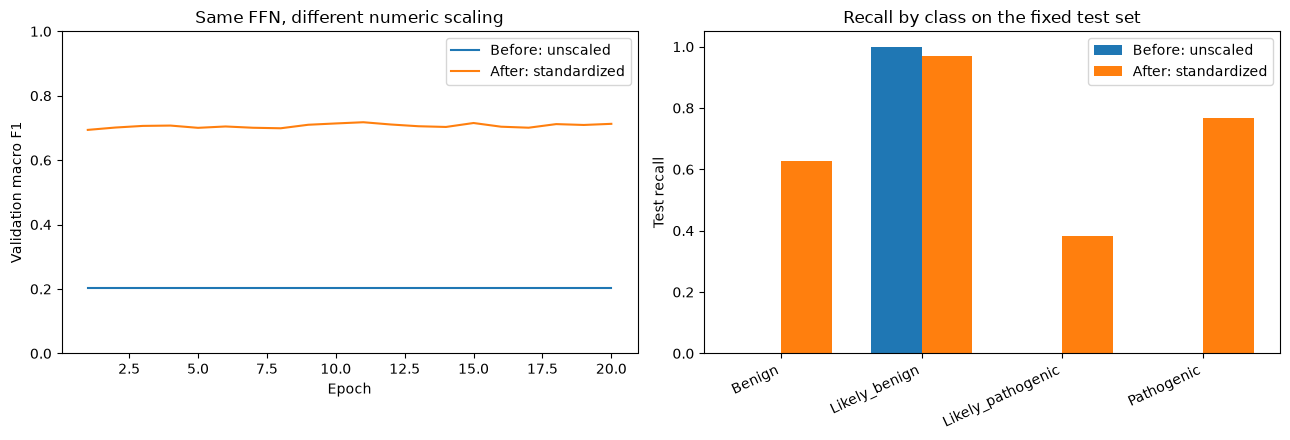

Test accuracy change (percentage points): 17.53066463256785
Test macro F1 change: 0.5120982330544717
Saved experiment results to: .\baseline_results\scaling_experiment


In [17]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(raw_history["epoch"], raw_history["validation_macro_f1"], label="Before: unscaled")
axes[0].plot(scaled_history["epoch"], scaled_history["validation_macro_f1"], label="After: standardized")
axes[0].set(xlabel="Epoch", ylabel="Validation macro F1", title="Same FFN, different numeric scaling", ylim=(0, 1))
axes[0].legend()
positions = np.arange(4)
raw_recall = [test_reports["unscaled"][name]["recall"] for name in class_names]
scaled_recall = [test_reports["scaled"][name]["recall"] for name in class_names]
axes[1].bar(positions-0.18, raw_recall, width=0.36, label="Before: unscaled")
axes[1].bar(positions+0.18, scaled_recall, width=0.36, label="After: standardized")
axes[1].set_xticks(positions, class_names, rotation=25, ha="right")
axes[1].set(ylabel="Test recall", title="Recall by class on the fixed test set", ylim=(0, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(EXPERIMENT_DIR / "scaling_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

experiment_record = {
    "experiment": "numeric_standardization_01", "seed": 42,
    "change": "StandardScaler on five numeric features; scaler fitted on X_fit only",
    "numeric_columns": numeric_cols,
    "fixed_configuration": {"hidden_dim": 64, "dropout": 0.3, "learning_rate": 0.001,
        "batch_size": 32, "epochs": 20, "optimizer": "Adam", "class_weights": None},
    "rows": {"fit": len(X_fit), "validation": len(X_val), "test": len(X_test)},
    "validation": validation_comparison.to_dict(orient="records"),
    "test": test_comparison.to_dict(orient="records"),
    "test_classification_reports": test_reports, "test_confusion_matrices": test_confusion_matrices,
    "versions": {"torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": __import__("sklearn").__version__},
    "limitation": "Full-dataset one-hot and gene-frequency encodings are inherited from the reproduced workflow.",
}
with (EXPERIMENT_DIR / "experiment_record.json").open("w", encoding="utf-8") as f:
    json.dump(experiment_record, f, indent=2)
print("Test accuracy change (percentage points):",
      100 * (test_rows[1]["accuracy"] - test_rows[0]["accuracy"]))
print("Test macro F1 change:", test_rows[1]["macro_f1"] - test_rows[0]["macro_f1"])
print("Saved experiment results to:", EXPERIMENT_DIR.resolve())


## Experiment 1 results: numeric standardization

The only experimental change was standardizing POS, AF_EXAC, AF_TGP, AF_ESP, and Primary_Gene_Freq.
The StandardScaler was fitted on 944,604 training rows only. Both runs used the same 236,151 validation rows,
the same 506,039 test rows, initial weights, seed 42, minibatch order, and original FFN settings.
Each model was trained for the predetermined 20 epochs. The earlier full-training baseline remains a separate reference.

| Test metric | Before: unscaled | After: standardized | Change |
|---|---:|---:|---:|
| Accuracy | 67.8764% | 85.4071% | +17.5307 pp |
| Macro F1 | 0.202170 | 0.714268 | +0.512098 |
| Balanced accuracy | 25.0004% | 68.7372% | +43.7368 pp |
| Benign recall | 0.0016% | 62.7116% | +62.7101 pp |
| Likely benign recall | 100.0000% | 96.9882% | -3.0118 pp |
| Likely pathogenic recall | 0.0000% | 38.3847% | +38.3847 pp |
| Pathogenic recall | 0.0000% | 76.8642% | +76.8642 pp |

Standardization is an input preprocessing change, not an FFN architecture change.
These results describe one seed and one fixed split. Full-dataset one-hot and gene-frequency encodings
were inherited from the reproduced workflow, so this is a controlled scaling comparison within that workflow,
not a fully leakage-free evaluation. Future parameter selection should use validation data rather than repeated test comparisons.


# Experiment 2: Increase the hidden layer from 64 to 128 units

Use the standardized 64-unit model from Experiment 1 as the control.
Reuse its exact fit/validation row indices and saved scaler. The only changed hyperparameter is hidden width.
Keep ReLU, Dropout=0.3, Adam lr=0.001, batch size=32, 20 epochs, and seed 42.
The explicit DataLoader generator also keeps minibatch order identical.
Different layer shapes require different initial weight tensors; both initializations use the same seed.

Compare the predetermined final epoch 20 using validation data only.
No new test evaluation is performed in this experiment. Earlier baseline and Experiment 1 cells and artifacts are retained.
The inherited full-dataset categorical/gene-frequency encoding limitation still applies.


## 21. Reuse the saved training/validation split and scaler

In [10]:
from sklearn.preprocessing import StandardScaler
import joblib

SCALING_DIR = OUTPUT_DIR / "scaling_experiment"
WIDTH_DIR = OUTPUT_DIR / "hidden128_experiment"
WIDTH_DIR.mkdir(parents=True, exist_ok=True)
saved_split = np.load(SCALING_DIR / "split_indices.npz")
width_fit_index = saved_split["fit_index"]
width_validation_index = saved_split["validation_index"]
saved_preprocessing = joblib.load(SCALING_DIR / "scaler.joblib")
width_scaler = saved_preprocessing["scaler"]
width_numeric_cols = saved_preprocessing["numeric_columns"]
assert X_e.columns.tolist() == saved_preprocessing["feature_columns"]
assert int(width_scaler.n_samples_seen_) == len(width_fit_index)

X_width_fit = X_e.loc[width_fit_index]
X_width_val = X_e.loc[width_validation_index]
y_width_fit = y.loc[width_fit_index]
y_width_val = y.loc[width_validation_index]
width_numeric_positions = [X_e.columns.get_loc(col) for col in width_numeric_cols]
width_fit_array = X_width_fit.to_numpy(dtype=np.float32)
width_val_array = X_width_val.to_numpy(dtype=np.float32)
width_fit_array[:, width_numeric_positions] = width_scaler.transform(X_width_fit[width_numeric_cols]).astype(np.float32)
width_val_array[:, width_numeric_positions] = width_scaler.transform(X_width_val[width_numeric_cols]).astype(np.float32)

print("Training rows:", len(width_fit_index))
print("Validation rows:", len(width_validation_index))
print("Scaler reused without refitting.")


Training rows: 944604
Validation rows: 236151
Scaler reused without refitting.


## 22. Change only hidden_dim from 64 to 128

The key modification is `hidden_dim_2 = 128`. Create a fresh model and optimizer rather than continuing
training from the 64-unit model. All remaining training settings match the standardized control.


In [11]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

hidden_dim_2 = 128
width_model = FFN(width_fit_array.shape[1], hidden_dim_2, 4)
width_criterion = nn.CrossEntropyLoss()
width_optimizer = optim.Adam(width_model.parameters(), lr=0.001)
width_dataset = TensorDataset(torch.from_numpy(width_fit_array), torch.tensor(y_width_fit.to_numpy(), dtype=torch.int64))
width_loader = DataLoader(width_dataset, batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
width_val_tensor = torch.from_numpy(width_val_array)
print(width_model)
print("Trainable parameters:", sum(p.numel() for p in width_model.parameters()))


FFN(
  (layer1): Linear(in_features=56, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (layer2): Linear(in_features=128, out_features=4, bias=True)
)
Trainable parameters: 7812


## 23. Train the 128-unit model for the same 20 epochs

In [12]:
width_history_rows = []
width_start = time.perf_counter()
for epoch in range(20):
    epoch_start = time.perf_counter()
    width_model.train()
    loss_sum = 0.0
    for batch_X, batch_y in width_loader:
        width_optimizer.zero_grad()
        scores = width_model(batch_X)
        loss = width_criterion(scores, batch_y)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss in the 128-unit experiment.")
        loss.backward()
        width_optimizer.step()
        loss_sum += loss.item() * len(batch_y)

    width_model.eval()
    with torch.no_grad():
        width_val_predictions = width_model(width_val_tensor).argmax(dim=1).numpy()
    val_accuracy = accuracy_score(y_width_val, width_val_predictions)
    val_macro_f1 = f1_score(y_width_val, width_val_predictions, average="macro", zero_division=0)
    width_history_rows.append({"epoch": epoch + 1, "training_loss": loss_sum / len(width_dataset),
        "validation_accuracy": val_accuracy, "validation_macro_f1": val_macro_f1,
        "seconds": time.perf_counter() - epoch_start})
    pd.DataFrame(width_history_rows).to_csv(WIDTH_DIR / "hidden128_history.csv", index=False)
    print(f"Hidden 128 | epoch {epoch+1:02d}/20 | loss={loss_sum/len(width_dataset):.6f} | "
          f"val_accuracy={val_accuracy:.6f} | val_macro_f1={val_macro_f1:.6f}", flush=True)

width_seconds = time.perf_counter() - width_start
width_history = pd.DataFrame(width_history_rows)
torch.save({"state_dict": width_model.state_dict(), "input_dim": width_fit_array.shape[1],
    "hidden_dim": hidden_dim_2, "output_dim": 4, "dropout": 0.3, "seed": 42,
    "scaling": "standard", "feature_columns": X_e.columns.tolist(),
    "numeric_columns": width_numeric_cols}, WIDTH_DIR / "hidden128_ffn.pt")
pd.DataFrame({"row_index": width_validation_index, "true_target": y_width_val.to_numpy(),
              "predicted_target": width_val_predictions}).to_csv(WIDTH_DIR / "hidden128_validation_predictions.csv", index=False)
print(f"Total training seconds: {width_seconds:.1f}")


Hidden 128 | epoch 01/20 | loss=0.405593 | val_accuracy=0.849355 | val_macro_f1=0.699836


Hidden 128 | epoch 02/20 | loss=0.388342 | val_accuracy=0.850629 | val_macro_f1=0.708408


Hidden 128 | epoch 03/20 | loss=0.384023 | val_accuracy=0.850710 | val_macro_f1=0.708456


Hidden 128 | epoch 04/20 | loss=0.381806 | val_accuracy=0.852819 | val_macro_f1=0.714542


Hidden 128 | epoch 05/20 | loss=0.380087 | val_accuracy=0.851066 | val_macro_f1=0.704114


...

Hidden 128 | epoch 17/20 | loss=0.372896 | val_accuracy=0.852010 | val_macro_f1=0.706115


Hidden 128 | epoch 18/20 | loss=0.372485 | val_accuracy=0.853602 | val_macro_f1=0.712870


Hidden 128 | epoch 19/20 | loss=0.372450 | val_accuracy=0.852899 | val_macro_f1=0.712999


Hidden 128 | epoch 20/20 | loss=0.372402 | val_accuracy=0.854373 | val_macro_f1=0.718025


Total training seconds: 313.7


## 24. Compare validation performance against the saved 64-unit control

Use the final-epoch validation predictions already saved by Experiment 1.
Keep the test results from Experiment 1 out of this width decision.


In [13]:
width_class_names = ["Benign", "Likely_benign", "Likely_pathogenic", "Pathogenic"]
control_predictions = pd.read_csv(SCALING_DIR / "scaled_validation_predictions.csv")
assert np.array_equal(control_predictions["row_index"].to_numpy(), width_validation_index)
assert np.array_equal(control_predictions["true_target"].to_numpy(), y_width_val.to_numpy())
control_history = pd.read_csv(SCALING_DIR / "scaled_history.csv")
with (SCALING_DIR / "experiment_record.json").open(encoding="utf-8") as f:
    previous_record = json.load(f)
control_seconds = previous_record["validation"][1]["training_seconds"]
control_checkpoint = torch.load(SCALING_DIR / "scaled_ffn.pt", map_location="cpu", weights_only=True)
control_parameters = sum(t.numel() for t in control_checkpoint["state_dict"].values())

width_comparison_rows = []
width_reports = {}
width_confusion_matrices = {}
for hidden_units, predictions, seconds, parameters in [
    (64, control_predictions["predicted_target"].to_numpy(), control_seconds, control_parameters),
    (128, width_val_predictions, width_seconds, sum(p.numel() for p in width_model.parameters())),
]:
    report = classification_report(y_width_val, predictions, labels=[0, 1, 2, 3],
                                   target_names=width_class_names, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_width_val, predictions, labels=[0, 1, 2, 3])
    row = {"hidden_units": hidden_units, "parameters": parameters,
        "validation_accuracy": accuracy_score(y_width_val, predictions),
        "validation_macro_f1": f1_score(y_width_val, predictions, average="macro", zero_division=0),
        "validation_balanced_accuracy": balanced_accuracy_score(y_width_val, predictions),
        "training_seconds": seconds}
    for name in width_class_names:
        row[f"recall_{name}"] = report[name]["recall"]
    width_comparison_rows.append(row)
    width_reports[str(hidden_units)] = report
    width_confusion_matrices[str(hidden_units)] = matrix.tolist()
    pd.DataFrame(report).T.to_csv(WIDTH_DIR / f"hidden{hidden_units}_validation_report.csv")
    pd.DataFrame(matrix, index=width_class_names, columns=width_class_names).to_csv(
        WIDTH_DIR / f"hidden{hidden_units}_validation_confusion_matrix.csv")
    print("Validation report: hidden units =", hidden_units)
    print(classification_report(y_width_val, predictions, labels=[0, 1, 2, 3],
                                target_names=width_class_names, zero_division=0))

width_comparison = pd.DataFrame(width_comparison_rows)
width_comparison.to_csv(WIDTH_DIR / "validation_comparison.csv", index=False)
display(width_comparison)
width_f1_change = width_comparison_rows[1]["validation_macro_f1"] - width_comparison_rows[0]["validation_macro_f1"]
preferred_hidden_units = 128 if width_f1_change > 0 else 64
print("Validation macro F1 change:", width_f1_change)
print("Preferred width by final-epoch validation macro F1:", preferred_hidden_units)
print("This is a single-seed comparison; a small difference is not evidence of a reliable advantage.")


Validation report: hidden units = 64


                   precision    recall  f1-score   support

           Benign       0.85      0.62      0.72     29353
    Likely_benign       0.90      0.97      0.93    160290
Likely_pathogenic       0.61      0.38      0.47     20605
       Pathogenic       0.70      0.77      0.73     25903

         accuracy                           0.85    236151
        macro avg       0.76      0.69      0.71    236151
     weighted avg       0.84      0.85      0.84    236151

Validation report: hidden units = 128
                   precision    recall  f1-score   support

           Benign       0.85      0.62      0.72     29353
    Likely_benign       0.90      0.97      0.93    160290
Likely_pathogenic       0.59      0.42      0.49     20605
       Pathogenic       0.70      0.77      0.73     25903

         accuracy                           0.85    236151
        macro avg       0.76      0.69      0.72    236151
     weighted avg       0.85      0.85      0.85    236151



,hidden_units,parameters,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,training_seconds,recall_Benign,recall_Likely_benign,recall_Likely_pathogenic,recall_Pathogenic
0,64,3908,0.853382,0.712790,0.686248,276.010089,0.624161,0.969518,0.381364,0.769949
1,128,7812,0.854373,0.718025,0.694142,313.678927,0.621265,0.966642,0.416744,0.771918


Validation macro F1 change: 0.0052348899333583
Preferred width by final-epoch validation macro F1: 128
This is a single-seed comparison; a small difference is not evidence of a reliable advantage.


## 25. Save the width comparison chart and experiment record

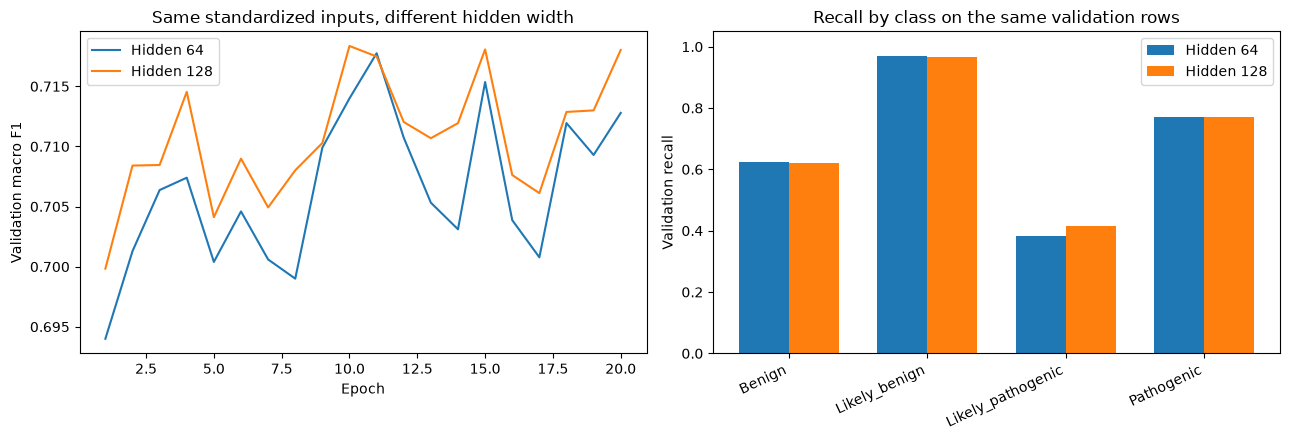

Saved width experiment to: .\baseline_results\hidden128_experiment


In [14]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(control_history["epoch"], control_history["validation_macro_f1"], label="Hidden 64")
axes[0].plot(width_history["epoch"], width_history["validation_macro_f1"], label="Hidden 128")
axes[0].set(xlabel="Epoch", ylabel="Validation macro F1", title="Same standardized inputs, different hidden width")
axes[0].legend()
positions = np.arange(4)
axes[1].bar(positions-0.18, [width_reports["64"][n]["recall"] for n in width_class_names], width=0.36, label="Hidden 64")
axes[1].bar(positions+0.18, [width_reports["128"][n]["recall"] for n in width_class_names], width=0.36, label="Hidden 128")
axes[1].set_xticks(positions, width_class_names, rotation=25, ha="right")
axes[1].set(ylabel="Validation recall", title="Recall by class on the same validation rows", ylim=(0, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(WIDTH_DIR / "hidden_width_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

width_record = {
    "experiment": "hidden_width_02", "change": "Hidden units: 64 -> 128", "seed": 42,
    "fixed_configuration": {"dropout": 0.3, "learning_rate": 0.001, "batch_size": 32,
        "epochs": 20, "optimizer": "Adam", "scaling": "standard", "class_weights": None},
    "fit_rows": len(width_fit_index), "validation_rows": len(width_validation_index),
    "split_source": str(SCALING_DIR / "split_indices.npz"),
    "scaler_source": str(SCALING_DIR / "scaler.joblib"),
    "validation": width_comparison_rows, "validation_classification_reports": width_reports,
    "validation_confusion_matrices": width_confusion_matrices,
    "macro_f1_change": float(width_f1_change), "preferred_hidden_units": preferred_hidden_units,
    "test_evaluated": False,
    "versions": {"torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": __import__("sklearn").__version__},
    "limitation": "One seed and one split; inherited full-dataset one-hot and gene-frequency encoding.",
}
with (WIDTH_DIR / "experiment_record.json").open("w", encoding="utf-8") as f:
    json.dump(width_record, f, indent=2)
print("Saved width experiment to:", WIDTH_DIR.resolve())


## Experiment 2 results: hidden width 64 to 128

Only hidden width changed. Both runs used standardized inputs, the same 944,604 training rows and 236,151 validation rows,
the saved Experiment 1 scaler, seed 42, minibatch order, and predetermined 20 epochs.
Dropout=0.3, Adam lr=0.001, batch size=32, and the four-class target remained unchanged.
The previously saved 64-unit model is the control. No additional test evaluation was performed.

| Validation metric | Hidden 64 | Hidden 128 | Change |
|---|---:|---:|---:|
| Accuracy | 85.3382% | 85.4373% | +0.0991 pp |
| Macro F1 | 0.712790 | 0.718025 | +0.005235 |
| Balanced accuracy | 68.6248% | 69.4142% | +0.7894 pp |
| Benign recall | 62.4161% | 62.1265% | -0.2896 pp |
| Likely benign recall | 96.9518% | 96.6642% | -0.2876 pp |
| Likely pathogenic recall | 38.1364% | 41.6744% | +3.5380 pp |
| Pathogenic recall | 76.9949% | 77.1918% | +0.1969 pp |
| Parameters | 3908 | 7812 | +3904 |
| Training seconds | 276.0 | 313.7 | +37.7 |

Final-epoch validation macro F1 favors hidden width 128 in this run.
The change in macro F1 is +0.005235. This is a single seed and one validation split;
a small difference does not establish a reliable advantage. Full-dataset one-hot and gene-frequency encodings remain
an inherited limitation. Use validation metrics for subsequent tuning and reserve test evaluation for the final selected configuration.

The next isolated experiment can change Dropout from 0.3 to 0.2 while keeping the selected width and all other settings fixed.
For reporting, record each change, validation macro F1, per-class recall, and training cost, including changes that do not improve results.


# Experiment 3: Reduce Dropout from 0.3 to 0.2

Keep standardized inputs and hidden width 128. Change only Dropout probability from 0.3 to 0.2.
Reuse the exact saved training/validation indices and scaler, seed 42, batch order, Adam lr=0.001,
batch size=32, and predetermined 20 epochs. Because the layer shapes and initialization seed are unchanged,
the two models start with the same initial weights.

Compare against the saved 128-unit, Dropout=0.3 model using final-epoch validation results only.
No additional test evaluation is performed. Previous experiment cells and outputs remain intact.
The inherited full-dataset one-hot and gene-frequency encoding limitation still applies.


## 26. Reuse the same data split and saved scaler

In [10]:
from sklearn.preprocessing import StandardScaler
import joblib

SCALING_DIR = OUTPUT_DIR / "scaling_experiment"
DROPOUT_DIR = OUTPUT_DIR / "dropout_experiment"
DROPOUT_DIR.mkdir(parents=True, exist_ok=True)
saved_split = np.load(SCALING_DIR / "split_indices.npz")
dropout_fit_index = saved_split["fit_index"]
dropout_validation_index = saved_split["validation_index"]
saved_preprocessing = joblib.load(SCALING_DIR / "scaler.joblib")
dropout_scaler = saved_preprocessing["scaler"]
dropout_numeric_cols = saved_preprocessing["numeric_columns"]
assert X_e.columns.tolist() == saved_preprocessing["feature_columns"]
assert int(dropout_scaler.n_samples_seen_) == len(dropout_fit_index)

X_dropout_fit = X_e.loc[dropout_fit_index]
X_dropout_val = X_e.loc[dropout_validation_index]
y_dropout_fit = y.loc[dropout_fit_index]
y_dropout_val = y.loc[dropout_validation_index]
dropout_numeric_positions = [X_e.columns.get_loc(col) for col in dropout_numeric_cols]
dropout_fit_array = X_dropout_fit.to_numpy(dtype=np.float32)
dropout_val_array = X_dropout_val.to_numpy(dtype=np.float32)
dropout_fit_array[:, dropout_numeric_positions] = dropout_scaler.transform(X_dropout_fit[dropout_numeric_cols]).astype(np.float32)
dropout_val_array[:, dropout_numeric_positions] = dropout_scaler.transform(X_dropout_val[dropout_numeric_cols]).astype(np.float32)

print("Training rows:", len(dropout_fit_index))
print("Validation rows:", len(dropout_validation_index))
print("Scaler reused without refitting.")

CONTROL_DIR = OUTPUT_DIR / "hidden128_experiment"


Training rows: 944604
Validation rows: 236151
Scaler reused without refitting.


## 27. Change only the Dropout probability

The key change is `dropout_3 = 0.2`, applied through `dropout_model.dropout.p`.
Start with a fresh 128-unit FFN and a fresh optimizer. The architecture and parameter count remain unchanged.


In [11]:
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
torch.set_num_threads(1)

dropout_3 = 0.2
dropout_model = FFN(dropout_fit_array.shape[1], 128, 4)
dropout_model.dropout.p = dropout_3
dropout_criterion = nn.CrossEntropyLoss()
dropout_optimizer = optim.Adam(dropout_model.parameters(), lr=0.001)
dropout_dataset = TensorDataset(torch.from_numpy(dropout_fit_array), torch.tensor(y_dropout_fit.to_numpy(), dtype=torch.int64))
dropout_loader = DataLoader(dropout_dataset, batch_size=32, shuffle=True,
                          generator=torch.Generator().manual_seed(42))
dropout_val_tensor = torch.from_numpy(dropout_val_array)
print(dropout_model)
print("Trainable parameters:", sum(p.numel() for p in dropout_model.parameters()))


FFN(
  (layer1): Linear(in_features=56, out_features=128, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.2, inplace=False)
  (layer2): Linear(in_features=128, out_features=4, bias=True)
)
Trainable parameters: 7812


## 28. Train the Dropout=0.2 model for the same 20 epochs

In [12]:
dropout_history_rows = []
dropout_start = time.perf_counter()
for epoch in range(20):
    epoch_start = time.perf_counter()
    dropout_model.train()
    loss_sum = 0.0
    for batch_X, batch_y in dropout_loader:
        dropout_optimizer.zero_grad()
        scores = dropout_model(batch_X)
        loss = dropout_criterion(scores, batch_y)
        if not torch.isfinite(loss):
            raise RuntimeError("Non-finite loss in the Dropout=0.2 experiment.")
        loss.backward()
        dropout_optimizer.step()
        loss_sum += loss.item() * len(batch_y)

    dropout_model.eval()
    with torch.no_grad():
        dropout_val_predictions = dropout_model(dropout_val_tensor).argmax(dim=1).numpy()
    val_accuracy = accuracy_score(y_dropout_val, dropout_val_predictions)
    val_macro_f1 = f1_score(y_dropout_val, dropout_val_predictions, average="macro", zero_division=0)
    dropout_history_rows.append({"epoch": epoch + 1, "training_loss": loss_sum / len(dropout_dataset),
        "validation_accuracy": val_accuracy, "validation_macro_f1": val_macro_f1,
        "seconds": time.perf_counter() - epoch_start})
    pd.DataFrame(dropout_history_rows).to_csv(DROPOUT_DIR / "dropout02_history.csv", index=False)
    print(f"Dropout 0.2 | epoch {epoch+1:02d}/20 | loss={loss_sum/len(dropout_dataset):.6f} | "
          f"val_accuracy={val_accuracy:.6f} | val_macro_f1={val_macro_f1:.6f}", flush=True)

dropout_seconds = time.perf_counter() - dropout_start
dropout_history = pd.DataFrame(dropout_history_rows)
torch.save({"state_dict": dropout_model.state_dict(), "input_dim": dropout_fit_array.shape[1],
    "hidden_dim": 128, "output_dim": 4, "dropout": dropout_3, "seed": 42,
    "scaling": "standard", "feature_columns": X_e.columns.tolist(),
    "numeric_columns": dropout_numeric_cols}, DROPOUT_DIR / "dropout02_ffn.pt")
pd.DataFrame({"row_index": dropout_validation_index, "true_target": y_dropout_val.to_numpy(),
              "predicted_target": dropout_val_predictions}).to_csv(DROPOUT_DIR / "dropout02_validation_predictions.csv", index=False)
print(f"Total training seconds: {dropout_seconds:.1f}")


Dropout 0.2 | epoch 01/20 | loss=0.402000 | val_accuracy=0.848851 | val_macro_f1=0.700019


Dropout 0.2 | epoch 02/20 | loss=0.384088 | val_accuracy=0.850380 | val_macro_f1=0.710638


Dropout 0.2 | epoch 03/20 | loss=0.379844 | val_accuracy=0.852251 | val_macro_f1=0.713204


Dropout 0.2 | epoch 04/20 | loss=0.377357 | val_accuracy=0.853268 | val_macro_f1=0.715450


Dropout 0.2 | epoch 05/20 | loss=0.375539 | val_accuracy=0.851498 | val_macro_f1=0.708546


...

Dropout 0.2 | epoch 17/20 | loss=0.368294 | val_accuracy=0.852539 | val_macro_f1=0.708464


Dropout 0.2 | epoch 18/20 | loss=0.367719 | val_accuracy=0.854225 | val_macro_f1=0.714499


Dropout 0.2 | epoch 19/20 | loss=0.367773 | val_accuracy=0.854470 | val_macro_f1=0.718972


Dropout 0.2 | epoch 20/20 | loss=0.367658 | val_accuracy=0.855135 | val_macro_f1=0.718276


Total training seconds: 326.9


## 29. Compare final-epoch validation results

Use the saved 128-unit Dropout=0.3 model as the control, rather than rerunning or overwriting it.
Choose between the two settings by validation macro F1. Per-class recall and training cost are also reported.


In [13]:
dropout_class_names = ["Benign", "Likely_benign", "Likely_pathogenic", "Pathogenic"]
dropout_control_predictions = pd.read_csv(CONTROL_DIR / "hidden128_validation_predictions.csv")
assert np.array_equal(dropout_control_predictions["row_index"].to_numpy(), dropout_validation_index)
assert np.array_equal(dropout_control_predictions["true_target"].to_numpy(), y_dropout_val.to_numpy())
dropout_control_history = pd.read_csv(CONTROL_DIR / "hidden128_history.csv")
with (CONTROL_DIR / "experiment_record.json").open(encoding="utf-8") as f:
    dropout_control_record = json.load(f)
dropout_control_seconds = dropout_control_record["validation"][1]["training_seconds"]

dropout_comparison_rows = []
dropout_reports = {}
dropout_matrices = {}
for probability, predictions, seconds in [
    (0.3, dropout_control_predictions["predicted_target"].to_numpy(), dropout_control_seconds),
    (0.2, dropout_val_predictions, dropout_seconds),
]:
    report = classification_report(y_dropout_val, predictions, labels=[0, 1, 2, 3],
                                  target_names=dropout_class_names, output_dict=True, zero_division=0)
    matrix = confusion_matrix(y_dropout_val, predictions, labels=[0, 1, 2, 3])
    row = {"dropout": probability, "hidden_units": 128,
        "parameters": sum(p.numel() for p in dropout_model.parameters()),
        "validation_accuracy": accuracy_score(y_dropout_val, predictions),
        "validation_macro_f1": f1_score(y_dropout_val, predictions, average="macro", zero_division=0),
        "validation_balanced_accuracy": balanced_accuracy_score(y_dropout_val, predictions),
        "training_seconds": seconds}
    for name in dropout_class_names:
        row[f"recall_{name}"] = report[name]["recall"]
    dropout_comparison_rows.append(row)
    dropout_reports[str(probability)] = report
    dropout_matrices[str(probability)] = matrix.tolist()
    filename_tag = str(probability).replace(".", "")
    pd.DataFrame(report).T.to_csv(DROPOUT_DIR / f"dropout{filename_tag}_validation_report.csv")
    pd.DataFrame(matrix, index=dropout_class_names, columns=dropout_class_names).to_csv(
        DROPOUT_DIR / f"dropout{filename_tag}_validation_confusion_matrix.csv")
    print("Validation report: Dropout =", probability)
    print(classification_report(y_dropout_val, predictions, labels=[0, 1, 2, 3],
                                target_names=dropout_class_names, zero_division=0))

dropout_comparison = pd.DataFrame(dropout_comparison_rows)
dropout_comparison.to_csv(DROPOUT_DIR / "validation_comparison.csv", index=False)
display(dropout_comparison)
dropout_f1_change = dropout_comparison_rows[1]["validation_macro_f1"] - dropout_comparison_rows[0]["validation_macro_f1"]
preferred_dropout = 0.2 if dropout_f1_change > 0 else 0.3
print("Validation macro F1 change:", dropout_f1_change)
print("Preferred Dropout by final-epoch validation macro F1:", preferred_dropout)
print("A small difference from one seed and one split does not establish a reliable advantage.")


Validation report: Dropout = 0.3


                   precision    recall  f1-score   support

           Benign       0.85      0.62      0.72     29353
    Likely_benign       0.90      0.97      0.93    160290
Likely_pathogenic       0.59      0.42      0.49     20605
       Pathogenic       0.70      0.77      0.73     25903

         accuracy                           0.85    236151
        macro avg       0.76      0.69      0.72    236151
     weighted avg       0.85      0.85      0.85    236151

Validation report: Dropout = 0.2
                   precision    recall  f1-score   support

           Benign       0.85      0.62      0.72     29353
    Likely_benign       0.90      0.97      0.93    160290
Likely_pathogenic       0.60      0.41      0.49     20605
       Pathogenic       0.70      0.78      0.73     25903

         accuracy                           0.86    236151
        macro avg       0.76      0.69      0.72    236151
     weighted avg       0.85      0.86      0.85    236151



,dropout,hidden_units,parameters,validation_accuracy,validation_macro_f1,validation_balanced_accuracy,training_seconds,recall_Benign,recall_Likely_benign,recall_Likely_pathogenic,recall_Pathogenic
0,0.3,128,7812,0.854373,0.718025,0.694142,313.678927,0.621265,0.966642,0.416744,0.771918
1,0.2,128,7812,0.855135,0.718276,0.693459,326.918077,0.619426,0.968226,0.408396,0.777786


Validation macro F1 change: 0.00025097075660673873
Preferred Dropout by final-epoch validation macro F1: 0.2
A small difference from one seed and one split does not establish a reliable advantage.


## 30. Save the Dropout comparison chart and experiment record

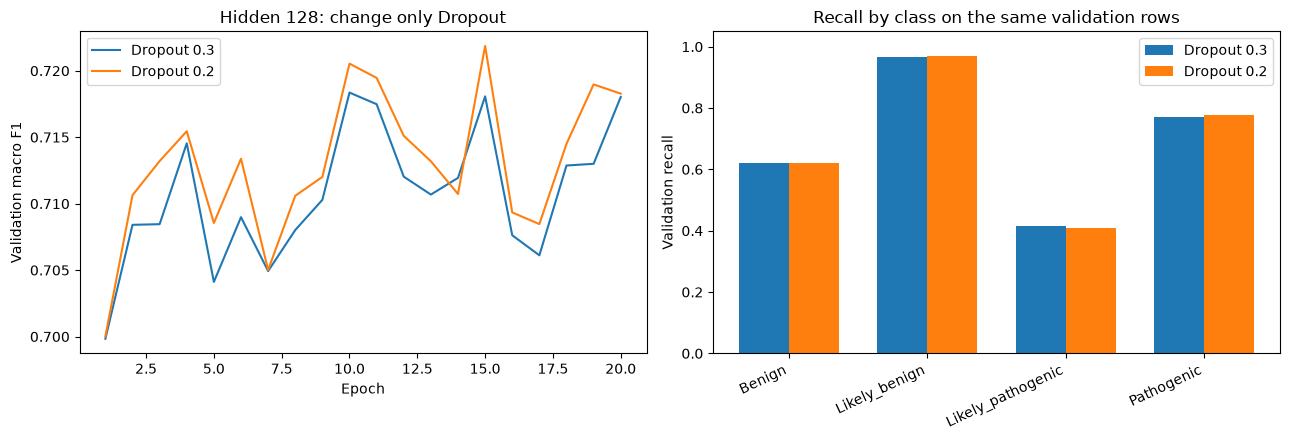

Saved Dropout experiment to: .\baseline_results\dropout_experiment


In [14]:
import matplotlib.pyplot as plt

dropout_history = pd.DataFrame(dropout_history_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(dropout_control_history["epoch"], dropout_control_history["validation_macro_f1"], label="Dropout 0.3")
axes[0].plot(dropout_history["epoch"], dropout_history["validation_macro_f1"], label="Dropout 0.2")
axes[0].set(xlabel="Epoch", ylabel="Validation macro F1", title="Hidden 128: change only Dropout")
axes[0].legend()
positions = np.arange(4)
axes[1].bar(positions-0.18, [dropout_reports["0.3"][n]["recall"] for n in dropout_class_names], width=0.36, label="Dropout 0.3")
axes[1].bar(positions+0.18, [dropout_reports["0.2"][n]["recall"] for n in dropout_class_names], width=0.36, label="Dropout 0.2")
axes[1].set_xticks(positions, dropout_class_names, rotation=25, ha="right")
axes[1].set(ylabel="Validation recall", title="Recall by class on the same validation rows", ylim=(0, 1.05))
axes[1].legend()
fig.tight_layout()
fig.savefig(DROPOUT_DIR / "dropout_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

dropout_record = {
    "experiment": "dropout_03", "change": "Dropout: 0.3 -> 0.2", "seed": 42,
    "fixed_configuration": {"hidden_dim": 128, "learning_rate": 0.001, "batch_size": 32,
        "epochs": 20, "optimizer": "Adam", "scaling": "standard", "class_weights": None},
    "fit_rows": len(dropout_fit_index), "validation_rows": len(dropout_validation_index),
    "split_source": str(SCALING_DIR / "split_indices.npz"),
    "scaler_source": str(SCALING_DIR / "scaler.joblib"),
    "validation": dropout_comparison_rows, "validation_classification_reports": dropout_reports,
    "validation_confusion_matrices": dropout_matrices,
    "macro_f1_change": float(dropout_f1_change), "preferred_dropout": preferred_dropout,
    "test_evaluated": False,
    "versions": {"torch": torch.__version__, "numpy": np.__version__, "pandas": pd.__version__,
                 "sklearn": __import__("sklearn").__version__},
    "limitation": "One seed and one split; inherited full-dataset one-hot and gene-frequency encoding.",
}
with (DROPOUT_DIR / "experiment_record.json").open("w", encoding="utf-8") as f:
    json.dump(dropout_record, f, indent=2)
print("Saved Dropout experiment to:", DROPOUT_DIR.resolve())


## Experiment 3 results: Dropout 0.3 to 0.2

Only the Dropout probability changed. Both runs used standardized inputs, hidden width 128, the same saved scaler,
944,604 training rows, 236,151 validation rows, initial weights, seed 42, and minibatch order.
Adam lr=0.001, batch size=32, and the predetermined 20 epochs remained unchanged.
The saved Dropout=0.3 model is the control. No additional test evaluation was performed.

| Validation metric | Dropout 0.3 | Dropout 0.2 | Change |
|---|---:|---:|---:|
| Accuracy | 85.4373% | 85.5135% | +0.0762 pp |
| Macro F1 | 0.718025 | 0.718276 | +0.000251 |
| Balanced accuracy | 69.4142% | 69.3459% | -0.0684 pp |
| Benign recall | 62.1265% | 61.9426% | -0.1840 pp |
| Likely benign recall | 96.6642% | 96.8226% | +0.1585 pp |
| Likely pathogenic recall | 41.6744% | 40.8396% | -0.8347 pp |
| Pathogenic recall | 77.1918% | 77.7786% | +0.5868 pp |
| Training seconds | 313.7 | 326.9 | +13.2 |

Final-epoch validation macro F1 favors Dropout=0.2 in this run.
The macro F1 change is +0.000251. One seed and one validation split cannot establish
whether a small difference is stable. The inherited full-dataset categorical and gene-frequency encoding limitation remains.

The experiment overview now records the unscaled control and all three modifications using validation metrics only.
For reporting, describe the substantial scaling improvement separately from smaller architecture/regularization effects.
Further confirmation can repeat promising configurations across several seeds using the same evaluation protocol.
Reserve test evaluation for the final selected configuration.


# Explain the selected FFN

Continue in this notebook so preprocessing, experimental results, and explanations remain together.
Choose the checkpoint with the highest previously recorded validation macro F1, not test performance.
Reload the trained weights without fitting another model or modifying any earlier experiment.

The explanation uses grouped permutation importance for the overall ranking and four small exact grouped SHAP
examples for local predictions. Both explain this fitted model under the inherited workflow, not biological causality.
The original full-dataset categorical/gene-frequency encoding limitation and single-seed limitation remain.


## 31. Select and reload the validation-best model

In [10]:
import joblib
import math
from IPython.display import Markdown

EXPLANATION_DIR = OUTPUT_DIR / "ffn_explanations"
EXPLANATION_DIR.mkdir(parents=True, exist_ok=True)
overview = pd.read_csv(OUTPUT_DIR / "experiment_overview.csv")
best_row = overview.loc[overview["validation_macro_f1"].idxmax()]
assert best_row["experiment"] == "Experiment 3: Dropout", "Review checkpoint selection after adding new experiments."
checkpoint_path = OUTPUT_DIR / "dropout_experiment" / "dropout02_ffn.pt"
selected_checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
selected_model = FFN(selected_checkpoint["input_dim"], selected_checkpoint["hidden_dim"], selected_checkpoint["output_dim"])
selected_model.dropout.p = selected_checkpoint["dropout"]
selected_model.load_state_dict(selected_checkpoint["state_dict"])
selected_model.eval()
torch.set_num_threads(1)

saved_preprocessing = joblib.load(OUTPUT_DIR / "scaling_experiment" / "scaler.joblib")
explanation_scaler = saved_preprocessing["scaler"]
explanation_numeric_cols = saved_preprocessing["numeric_columns"]
assert X_e.columns.tolist() == selected_checkpoint["feature_columns"] == saved_preprocessing["feature_columns"]
explanation_numeric_positions = [X_e.columns.get_loc(c) for c in explanation_numeric_cols]
saved_indices = np.load(OUTPUT_DIR / "scaling_experiment" / "split_indices.npz")
explanation_fit_index = saved_indices["fit_index"]
explanation_val_index = saved_indices["validation_index"]
assert int(explanation_scaler.n_samples_seen_) == len(explanation_fit_index)
explanation_class_names = ["Benign", "Likely_benign", "Likely_pathogenic", "Pathogenic"]

def explanation_array(row_index):
    frame = X_e.loc[row_index]
    result = frame.to_numpy(dtype=np.float32)
    result[:, explanation_numeric_positions] = explanation_scaler.transform(frame[explanation_numeric_cols]).astype(np.float32)
    return result

def predict_probabilities(array):
    with torch.no_grad():
        return torch.softmax(selected_model(torch.from_numpy(np.ascontiguousarray(array))), dim=1).numpy()

explanation_val_array = explanation_array(explanation_val_index)
explanation_val_probabilities = predict_probabilities(explanation_val_array)
explanation_val_predictions = explanation_val_probabilities.argmax(axis=1)
prediction_path = OUTPUT_DIR / "dropout_experiment" / "dropout02_validation_predictions.csv"
if not prediction_path.exists():
    pd.DataFrame({"row_index": explanation_val_index,
                  "true_target": y.loc[explanation_val_index].to_numpy(),
                  "predicted_target": explanation_val_predictions}).to_csv(prediction_path, index=False)
stored_predictions = pd.read_csv(prediction_path)
assert np.array_equal(stored_predictions["row_index"].to_numpy(), explanation_val_index)
assert np.array_equal(stored_predictions["predicted_target"].to_numpy(), explanation_val_predictions)
full_validation_f1 = f1_score(y.loc[explanation_val_index], explanation_val_predictions, average="macro", zero_division=0)
assert np.isclose(full_validation_f1, best_row["validation_macro_f1"])
selection = {"criterion": "highest recorded validation macro F1", "checkpoint": str(checkpoint_path),
    "hidden_dim": selected_checkpoint["hidden_dim"], "dropout": selected_checkpoint["dropout"],
    "learning_rate": 0.001, "batch_size": 32, "epochs": 20, "scaling": "standard", "seed": 42,
    "validation_accuracy": float(best_row["validation_accuracy"]), "validation_macro_f1": float(full_validation_f1),
    "selection_caveat": "Dropout 0.2 exceeds 0.3 by only about 0.000251 macro F1 for one seed and split."}
with (EXPLANATION_DIR / "selected_model.json").open("w", encoding="utf-8") as f:
    json.dump(selection, f, indent=2)
display(overview.sort_values("validation_macro_f1", ascending=False))
print("Selected model:", selection)
print("Reloaded model exactly matches the saved validation predictions.")


Selected model: {'criterion': 'highest recorded validation macro F1', 'checkpoint': 'baseline_results\\dropout_experiment\\dropout02_ffn.pt', 'hidden_dim': 128, 'dropout': 0.2, 'learning_rate': 0.001, 'batch_size': 32, 'epochs': 20, 'scaling': 'standard', 'seed': 42, 'validation_accuracy': 0.8551350618883681, 'validation_macro_f1': 0.7182762452928837, 'selection_caveat': 'Dropout 0.2 exceeds 0.3 by only about 0.000251 macro F1 for one seed and split.'}
Reloaded model exactly matches the saved validation predictions.


,experiment,numeric_scaling,hidden_units,validation_accuracy,validation_macro_f1,training_seconds,dropout
3,Experiment 3: Dropout,standard,128,0.855135,0.718276,326.918077,0.2
2,Experiment 2: hidden width,standard,128,0.854373,0.718025,313.678927,0.3
1,Experiment 1: standardization,standard,64,0.853382,0.712790,276.010089,0.3
0,Unscaled control,none,64,0.678761,0.202161,307.398330,0.3


## 32. Define eight meaningful feature groups

The FFN has 56 encoded inputs, but the report uses eight source-feature groups.
Shuffle all one-hot columns belonging to the same categorical variable together, preserving valid category patterns.
Primary_Gene_Freq is the count of the primary gene in this dataset; the model does not receive gene identity directly.


In [11]:
feature_groups = {}
for name in ["CHROM", "POS", "AF_EXAC", "AF_TGP", "AF_ESP", "CLNVC", "MC_Clean", "Primary_Gene_Freq"]:
    if name in ["CHROM", "CLNVC", "MC_Clean"]:
        feature_groups[name] = [i for i, c in enumerate(X_e.columns) if c.startswith(name + "_")]
    else:
        feature_groups[name] = [X_e.columns.get_loc(name)]
assert sorted(i for indices in feature_groups.values() for i in indices) == list(range(X_e.shape[1]))
assert all(len(indices) > 0 for indices in feature_groups.values())

feature_meanings = {
    "CHROM": ("Chromosome", "Chromosome containing the variant.",
        "Reliance can reflect chromosome-specific annotation and sampling patterns; it is not a causal explanation."),
    "POS": ("Genomic position", "Coordinate of the variant within its chromosome.",
        "Coordinate dependence can reflect genomic context or dataset composition; a larger coordinate does not mean greater pathogenicity."),
    "AF_EXAC": ("ExAC allele frequency", "Allele frequency reported from ExAC.",
        "The model can use population-frequency patterns. Missing or invalid values were filled with zero, so zero is ambiguous."),
    "AF_TGP": ("1000 Genomes allele frequency", "Allele frequency reported from the 1000 Genomes Project.",
        "This supplies another population-frequency measurement. Correlation with the other frequency fields can distribute importance."),
    "AF_ESP": ("GO-ESP allele frequency", "Allele frequency reported from GO-ESP.",
        "Interpret as dependence on this population-frequency field, not a universal pathogenicity threshold. Missing values were filled with zero."),
    "CLNVC": ("Variant type", "Structural category of the change, such as a single-nucleotide variant, insertion, or deletion.",
        "The FFN uses differences between variant categories; the permutation score does not specify which category raises each class probability."),
    "MC_Clean": ("Molecular consequence", "Text description of the first predicted molecular consequence retained from MC.",
        "The FFN uses consequence categories such as missense, synonymous, or frameshift. This is a model association; additional consequences were discarded during cleaning."),
    "Primary_Gene_Freq": ("Gene occurrence count", "Number of dataset rows assigned to the extracted primary gene.",
        "This is a dataset-frequency proxy, not gene expression, gene identity, or biological gene importance. Full-dataset counting is an inherited evaluation limitation."),
}
with (EXPLANATION_DIR / "feature_groups.json").open("w", encoding="utf-8") as f:
    json.dump({k: [X_e.columns[i] for i in v] for k, v in feature_groups.items()}, f, indent=2)
display(pd.DataFrame([{"feature": k, "encoded_columns": len(v), "meaning": feature_meanings[k][1]}
                     for k, v in feature_groups.items()]))


,feature,encoded_columns,meaning
0,CHROM,26,Chromosome containing the variant.
1,POS,1,Coordinate of the variant within its chromosome.
2,AF_EXAC,1,Allele frequency reported from ExAC.
3,AF_TGP,1,Allele frequency reported from the 1000 Genome...
4,AF_ESP,1,Allele frequency reported from GO-ESP.
5,CLNVC,7,"Structural category of the change, such as a s..."
6,MC_Clean,18,Text description of the first predicted molecu...
7,Primary_Gene_Freq,1,Number of dataset rows assigned to the extract...


## 33. Overall feature importance: grouped permutation importance

Use 30,000 stratified validation rows and 10 random permutations per feature group.
Importance is the baseline sample macro F1 minus macro F1 after shuffling a group.
Larger positive values mean the fitted FFN relies more on that group for this score.
Error bars show one standard deviation over permutations, not confidence intervals across model fits.
Correlated or interacting features can share importance, and permutation can create uncommon feature combinations.


CHROM macro F1 drop: 0.02415001432535239
POS macro F1 drop: 0.00673265117339168
AF_EXAC macro F1 drop: 0.012574393748927349
AF_TGP macro F1 drop: 0.13790529051428094
AF_ESP macro F1 drop: 0.017613446380003728
CLNVC macro F1 drop: 0.011124530319314829
MC_Clean macro F1 drop: 0.29429923893198023
Primary_Gene_Freq macro F1 drop: 0.036526783725568356


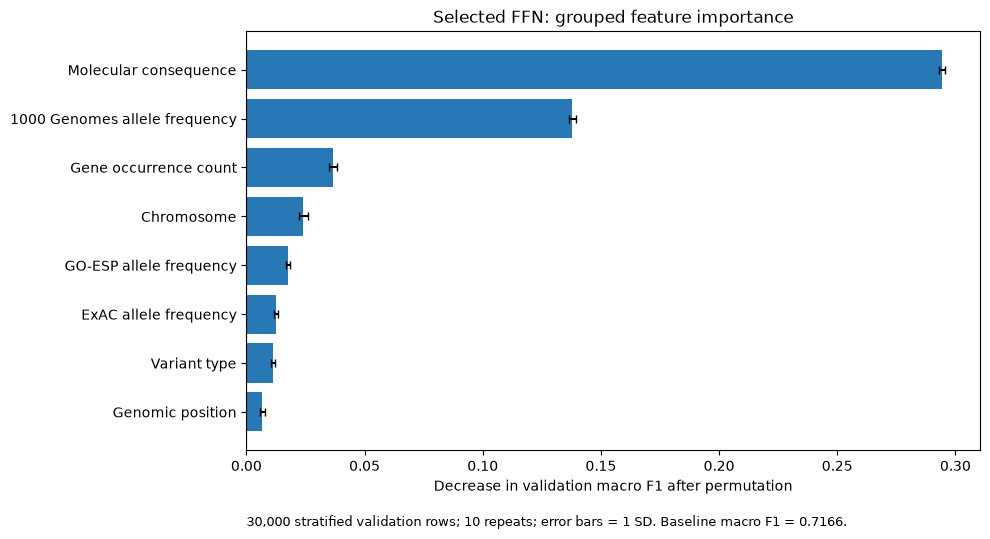

,feature,mean_macro_f1_drop,std_macro_f1_drop
0,MC_Clean,0.294299,0.001317
1,AF_TGP,0.137905,0.001593
2,Primary_Gene_Freq,0.036527,0.001648
3,CHROM,0.024150,0.001737
4,AF_ESP,0.017613,0.000908
5,AF_EXAC,0.012574,0.000770
6,CLNVC,0.011125,0.000788
7,POS,0.006733,0.000947


In [12]:
_, importance_index = train_test_split(explanation_val_index, test_size=30000, random_state=42,
                                       stratify=y.loc[explanation_val_index])
importance_positions = pd.Index(explanation_val_index).get_indexer(importance_index)
assert (importance_positions >= 0).all()
importance_array = explanation_val_array[importance_positions].copy()
importance_truth = y.loc[importance_index].to_numpy()
importance_baseline = f1_score(importance_truth, predict_probabilities(importance_array).argmax(axis=1),
                               average="macro", zero_division=0)
permutation_rng = np.random.default_rng(42)
importance_rows = []
for feature, positions in feature_groups.items():
    drops = []
    for repeat in range(10):
        order = permutation_rng.permutation(len(importance_array))
        shuffled = importance_array.copy()
        shuffled[:, positions] = importance_array[order][:, positions]
        score = f1_score(importance_truth, predict_probabilities(shuffled).argmax(axis=1), average="macro", zero_division=0)
        drops.append(float(importance_baseline - score))
    importance_rows.append({"feature": feature, "display_name": feature_meanings[feature][0],
        "mean_macro_f1_drop": float(np.mean(drops)), "std_macro_f1_drop": float(np.std(drops, ddof=1)),
        "encoded_columns": len(positions), **{f"repeat_{i+1}": value for i, value in enumerate(drops)}})
    print(feature, "macro F1 drop:", np.mean(drops), flush=True)
importance_table = pd.DataFrame(importance_rows).sort_values("mean_macro_f1_drop", ascending=False).reset_index(drop=True)
importance_table.to_csv(EXPLANATION_DIR / "grouped_permutation_importance.csv", index=False)
np.save(EXPLANATION_DIR / "importance_validation_indices.npy", importance_index)

import matplotlib.pyplot as plt
chart_data = importance_table.iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(chart_data["display_name"], chart_data["mean_macro_f1_drop"], xerr=chart_data["std_macro_f1_drop"],
        color="#2878b5", capsize=3)
ax.axvline(0, color="black", linewidth=0.8)
ax.set(xlabel="Decrease in validation macro F1 after permutation", title="Selected FFN: grouped feature importance")
ax.text(0, -0.18, f"30,000 stratified validation rows; 10 repeats; error bars = 1 SD. Baseline macro F1 = {importance_baseline:.4f}.",
        transform=ax.transAxes, fontsize=9)
fig.tight_layout()
fig.savefig(EXPLANATION_DIR / "global_feature_importance.png", dpi=200, bbox_inches="tight")
fig.savefig(EXPLANATION_DIR / "global_feature_importance.svg", bbox_inches="tight")
plt.show()
display(importance_table[["feature", "mean_macro_f1_drop", "std_macro_f1_drop"]])


## 34. Explain the leading features

Feature definitions follow ClinVar field descriptions; interpretations below are limited to this trained FFN.
Permutation importance measures model dependence, not direction, biological causality, or the intrinsic value of a feature.
For direction in an individual prediction, use the local class-specific Shapley examples below.


In [13]:
feature_explanations = importance_table[["feature", "mean_macro_f1_drop", "std_macro_f1_drop"]].copy()
feature_explanations["meaning"] = feature_explanations["feature"].map(lambda f: feature_meanings[f][1])
feature_explanations["interpretation"] = feature_explanations["feature"].map(lambda f: feature_meanings[f][2])
feature_explanations.to_csv(EXPLANATION_DIR / "feature_meanings_and_interpretation.csv", index=False)
top_feature_text = "## Leading features for this FFN\n\n"
for rank, row in feature_explanations.head(5).iterrows():
    top_feature_text += f"{rank+1}. **{row['feature']}**: mean macro F1 decrease {row['mean_macro_f1_drop']:.4f}. "
    top_feature_text += row["meaning"] + " " + row["interpretation"] + "\n\n"
display(Markdown(top_feature_text))


## Leading features for this FFN

1. **MC_Clean**: mean macro F1 decrease 0.2943. Text description of the first predicted molecular consequence retained from MC. The FFN uses consequence categories such as missense, synonymous, or frameshift. This is a model association; additional consequences were discarded during cleaning.

2. **AF_TGP**: mean macro F1 decrease 0.1379. Allele frequency reported from the 1000 Genomes Project. This supplies another population-frequency measurement. Correlation with the other frequency fields can distribute importance.

3. **Primary_Gene_Freq**: mean macro F1 decrease 0.0365. Number of dataset rows assigned to the extracted primary gene. This is a dataset-frequency proxy, not gene expression, gene identity, or biological gene importance. Full-dataset counting is an inherited evaluation limitation.

4. **CHROM**: mean macro F1 decrease 0.0242. Chromosome containing the variant. Reliance can reflect chromosome-specific annotation and sampling patterns; it is not a causal explanation.

5. **AF_ESP**: mean macro F1 decrease 0.0176. Allele frequency reported from GO-ESP. Interpret as dependence on this population-frequency field, not a universal pathogenicity threshold. Missing values were filled with zero.



## 35. Four local grouped SHAP cases: correct predictions and errors

Explain two correct predictions (Benign and Pathogenic) and two errors (true Likely_pathogenic and true Pathogenic).
Take the first matching validation row in the saved validation order; these are illustrative, not representative clinical cases.

Use exact Shapley enumeration over the eight feature groups, with 64 stratified training-background rows.
For each coalition, replace absent groups with background values and average the model's softmax probabilities.
Enumerate all 256 coalitions and compute class-specific Shapley values with the factorial weights.
This is an exact grouped interventional SHAP calculation for this empirical background; it does not use the SHAP package.
The background expectation plus the eight contributions must reconstruct each class probability.

Positive bars raise the displayed predicted-class probability relative to the background expectation; negative bars lower it.
Interventional replacements may break feature correlations. Results depend on the selected groups and background,
and do not establish causal or clinical effects. Values are in model-probability units, not calibrated clinical risk.


,case,row_index,true_label,predicted_label,predicted_probability,true_class_probability,background_predicted_class_probability,max_additivity_error,CHROM,POS,Primary_Gene,CLNVC,MC_Clean,AF_EXAC,AF_TGP,AF_ESP,Primary_Gene_Freq
0,Correct Benign,1002402,Benign,Benign,0.623420,0.623420,0.112130,1.788139e-07,12,32751364,FGD4,single_nucleotide_variant,intron_variant,0.0,0.02117,0.0,388
1,Correct Pathogenic,1645645,Pathogenic,Pathogenic,0.721890,0.721890,0.089342,5.960464e-08,X,70330527,IL2RG,single_nucleotide_variant,nonsense,0.0,0.00000,0.0,368
2,Misclassified Likely_pathogenic,663701,Likely_pathogenic,Pathogenic,0.690131,0.305438,0.089342,5.960464e-08,7,104747644,KMT2E,Deletion,frameshift_variant,0.0,0.00000,0.0,610
3,Misclassified Pathogenic,1456437,Pathogenic,Likely_pathogenic,0.616970,0.236489,0.089391,5.960464e-08,19,11216243,LDLR,single_nucleotide_variant,missense_variant,0.0,0.00000,0.0,2940


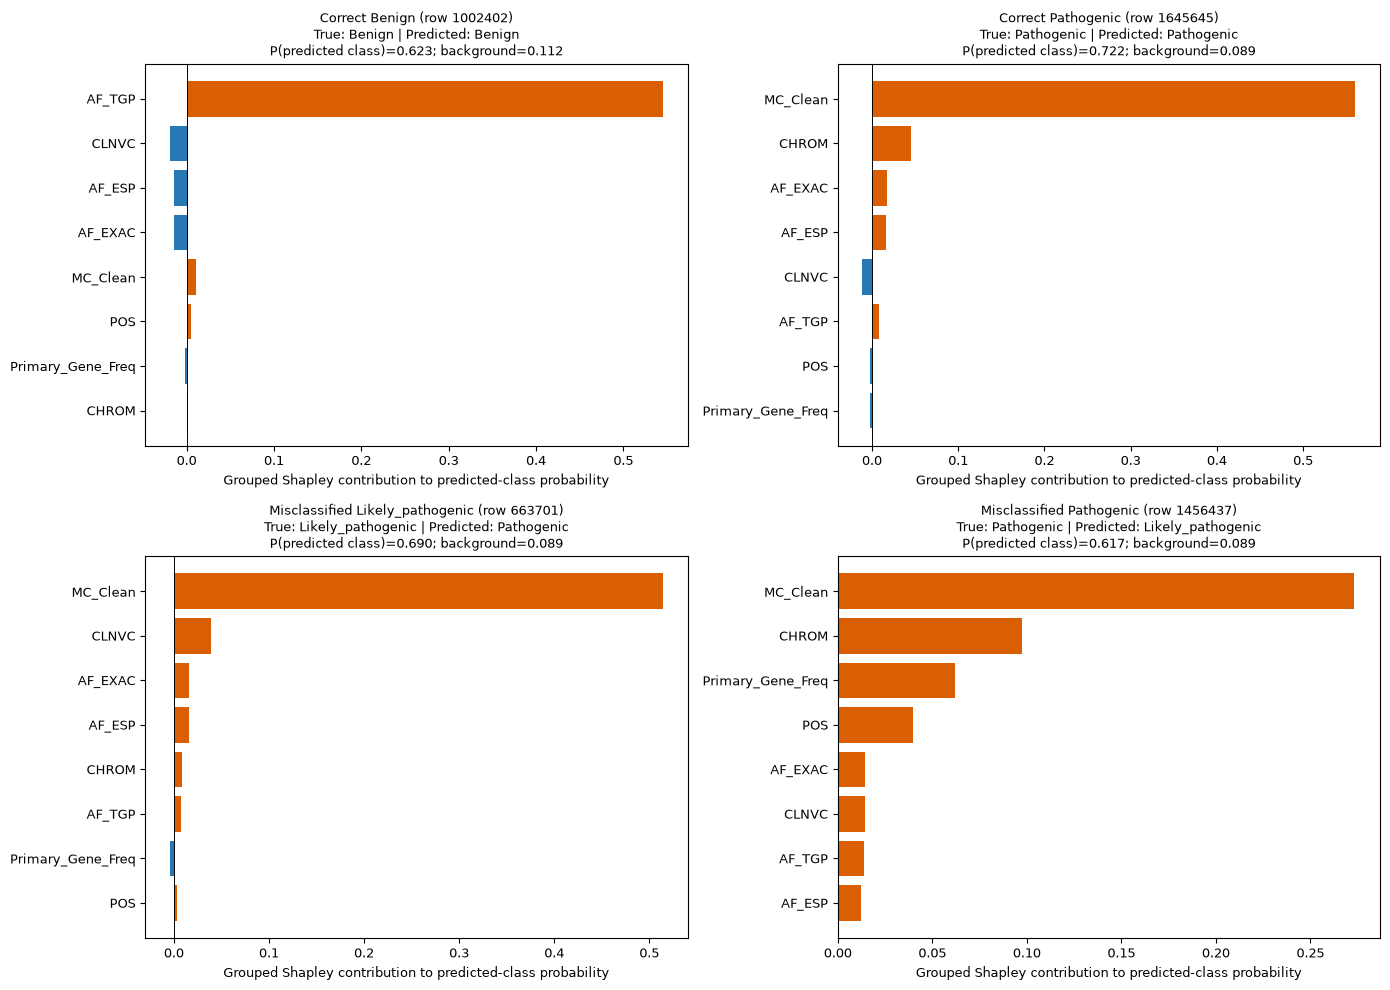

In [14]:
validation_truth = y.loc[explanation_val_index].to_numpy()
case_conditions = [
    ("Correct Benign", (validation_truth == 0) & (explanation_val_predictions == 0)),
    ("Correct Pathogenic", (validation_truth == 3) & (explanation_val_predictions == 3)),
    ("Misclassified Likely_pathogenic", (validation_truth == 2) & (explanation_val_predictions != 2)),
    ("Misclassified Pathogenic", (validation_truth == 3) & (explanation_val_predictions != 3)),
]
case_positions = [int(np.flatnonzero(condition)[0]) for _, condition in case_conditions]
assert len(set(case_positions)) == 4
_, background_index = train_test_split(explanation_fit_index, test_size=64, random_state=42,
                                      stratify=y.loc[explanation_fit_index])
background_array = explanation_array(background_index)
np.save(EXPLANATION_DIR / "shap_training_background_indices.npy", background_index)
group_names = list(feature_groups)
number_of_groups = len(group_names)
coalition_count = 2 ** number_of_groups

def exact_group_shap(case_array):
    coalition_inputs = []
    for mask in range(coalition_count):
        masked = background_array.copy()
        for group_number, feature in enumerate(group_names):
            if mask & (1 << group_number):
                columns = feature_groups[feature]
                masked[:, columns] = case_array[columns]
        coalition_inputs.append(masked)
    coalition_values = predict_probabilities(np.concatenate(coalition_inputs)).reshape(coalition_count, len(background_array), 4).mean(axis=1, dtype=np.float64)
    phi = np.zeros((number_of_groups, 4))
    for group_number in range(number_of_groups):
        for mask in range(coalition_count):
            if mask & (1 << group_number):
                continue
            size = mask.bit_count()
            weight = math.factorial(size) * math.factorial(number_of_groups-size-1) / math.factorial(number_of_groups)
            phi[group_number] += weight * (coalition_values[mask | (1 << group_number)] - coalition_values[mask])
    expected = coalition_values[0]
    actual = predict_probabilities(case_array[None, :])[0]
    residual = actual - (expected + phi.sum(axis=0))
    assert np.max(np.abs(residual)) < 1e-6
    return phi, expected, actual, residual

local_rows = []
local_case_rows = []
local_plot_data = []
for (case_label, _), position in zip(case_conditions, case_positions):
    row_index = int(explanation_val_index[position])
    phi, expected, actual, residual = exact_group_shap(explanation_val_array[position])
    predicted_class = int(explanation_val_predictions[position])
    true_class = int(validation_truth[position])
    case_info = {"case": case_label, "row_index": row_index,
        "true_label": explanation_class_names[true_class], "predicted_label": explanation_class_names[predicted_class],
        "predicted_probability": float(actual[predicted_class]), "true_class_probability": float(actual[true_class]),
        "background_predicted_class_probability": float(expected[predicted_class]),
        "max_additivity_error": float(np.max(np.abs(residual)))}
    for field in ["CHROM", "POS", "Primary_Gene", "CLNVC", "MC_Clean", "AF_EXAC", "AF_TGP", "AF_ESP"]:
        case_info[field] = data_ready.loc[row_index, field]
    case_info["Primary_Gene_Freq"] = int(X_e.loc[row_index, "Primary_Gene_Freq"])
    local_case_rows.append(case_info)
    for group_number, feature in enumerate(group_names):
        for class_number, name in enumerate(explanation_class_names):
            local_rows.append({"case": case_label, "row_index": row_index, "feature": feature,
                "class": name, "shap_value": float(phi[group_number, class_number]),
                "background_probability": float(expected[class_number]), "prediction_probability": float(actual[class_number])})
    local_plot_data.append((case_info, phi[:, predicted_class]))

local_cases = pd.DataFrame(local_case_rows)
local_shap = pd.DataFrame(local_rows)
local_cases.to_csv(EXPLANATION_DIR / "local_cases.csv", index=False)
local_shap.to_csv(EXPLANATION_DIR / "local_grouped_shap_values.csv", index=False)
display(local_cases)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for ax, (info, values) in zip(axes.flat, local_plot_data):
    order = np.argsort(np.abs(values))
    ax.barh(np.array(group_names)[order], values[order], color=np.where(values[order] >= 0, "#d95f02", "#2878b5"))
    ax.axvline(0, color="black", linewidth=0.7)
    ax.set_title(f"{info['case']} (row {info['row_index']})\nTrue: {info['true_label']} | Predicted: {info['predicted_label']}\n"
        f"P(predicted class)={info['predicted_probability']:.3f}; background={info['background_predicted_class_probability']:.3f}", fontsize=9)
    ax.set_xlabel("Grouped Shapley contribution to predicted-class probability", fontsize=9)
    ax.tick_params(labelsize=9)
fig.tight_layout()
fig.savefig(EXPLANATION_DIR / "local_grouped_shap_cases.png", dpi=180, bbox_inches="tight")
plt.show()


## 36. Save the explanation report and interpretation limits

Sources for the method and feature definitions:
- [Permutation importance documentation](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [Exact SHAP enumeration and background masking](https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html)
- [ClinVar field descriptions by the database authors](https://academic.oup.com/nar/article/46/D1/D1062/4641904)

The SHAP reference describes exact enumeration; the local calculation here is implemented directly for eight groups.


In [15]:
explanation_report = "# Explanation of the selected FFN\n\n"
explanation_report += "## Selected configuration\n\n"
explanation_report += f"Standardized numeric inputs; hidden width 128; Dropout 0.2; Adam lr=0.001; batch size 32; 20 epochs; seed 42. Validation accuracy={selection['validation_accuracy']:.6f}, macro F1={selection['validation_macro_f1']:.6f}. "
explanation_report += "This is the highest recorded validation macro F1 among tested configurations; its advantage over Dropout 0.3 is only about 0.000251 for one seed. No new model training or test evaluation was performed.\n\n"
explanation_report += "## Global feature importance\n\n"
explanation_report += f"Grouped permutation importance on 30,000 stratified validation rows, 10 repeats; sample baseline macro F1={importance_baseline:.6f}. Error bars show one permutation SD.\n\n"
explanation_report += "| Feature | Mean macro F1 decrease | SD |\n|---|---:|---:|\n"
for _, row in importance_table.iterrows():
    explanation_report += f"| {row['feature']} | {row['mean_macro_f1_drop']:.6f} | {row['std_macro_f1_drop']:.6f} |\n"
explanation_report += "\n" + top_feature_text + "\n## Local grouped SHAP examples\n\n"
explanation_report += "Exact enumeration over eight groups (256 coalitions) with 64 stratified training-background rows; all four class outputs are explained. Cases are the first validation rows matching the stated correct/error categories.\n\n"
for info, values in local_plot_data:
    order = np.argsort(values)[::-1]
    top_positive = [i for i in order if values[i] > 0][:2]
    top_negative = [i for i in np.argsort(values) if values[i] < 0][:2]
    explanation_report += f"### {info['case']} (row {info['row_index']})\n\n"
    explanation_report += f"True label: {info['true_label']}; predicted label: {info['predicted_label']}; model probability for the predicted class: {info['predicted_probability']:.4f}; probability for the true class: {info['true_class_probability']:.4f}. "
    explanation_report += f"Observed MC_Clean={info['MC_Clean']}, CLNVC={info['CLNVC']}, primary gene={info['Primary_Gene']}. The model uses gene frequency, not the gene name.\n\n"
    explanation_report += "Largest positive contributions to the predicted class: " + ", ".join(f"{group_names[i]} ({values[i]:+.4f})" for i in top_positive) + ". "
    if top_negative:
        explanation_report += "Largest negative contributions: " + ", ".join(f"{group_names[i]} ({values[i]:+.4f})" for i in top_negative) + ".\n\n"
    else:
        explanation_report += "No negative contributions to this predicted class under the selected background.\n\n"
explanation_report += "## Limits\n\nThe ranking explains model reliance, not biological causality. Permutation gives no universal direction of effect. Population-frequency fields are correlated, and absent frequencies were filled with zero. Gene frequency is a dataset-count proxy learned from the full dataset in the inherited workflow; this prevents a strictly leakage-free interpretation. Local interventional masking can break feature correlations, uses only 64 reference rows, and depends on the chosen grouping. Softmax outputs are model probabilities, not calibrated clinical risks. One seed and a fixed split do not establish stable superiority of the selected hyperparameters.\n\n"
explanation_report += "## References\n\n- https://scikit-learn.org/stable/modules/permutation_importance.html\n- https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html\n- https://academic.oup.com/nar/article/46/D1/D1062/4641904\n"
(EXPLANATION_DIR / "ffn_explanation_summary.md").write_text(explanation_report, encoding="utf-8")
explanation_record = {"selected_model": selection, "global_method": "grouped permutation macro F1 decrease",
    "validation_sample_rows": len(importance_index), "permutation_repeats": 10,
    "sample_baseline_macro_f1": float(importance_baseline), "feature_groups": feature_groups,
    "local_method": "exact grouped interventional Shapley values on softmax probabilities",
    "coalitions_per_case": coalition_count, "training_background_rows": len(background_index), "case_count": len(local_cases),
    "max_local_additivity_error": float(local_cases["max_additivity_error"].max()),
    "test_evaluated": False, "model_retrained": False}
with (EXPLANATION_DIR / "explanation_record.json").open("w", encoding="utf-8") as f:
    json.dump(explanation_record, f, indent=2)
display(Markdown(explanation_report))
print("Saved model explanations to:", EXPLANATION_DIR.resolve())


Saved model explanations to: .\baseline_results\ffn_explanations


# Explanation of the selected FFN

## Selected configuration

Standardized numeric inputs; hidden width 128; Dropout 0.2; Adam lr=0.001; batch size 32; 20 epochs; seed 42. Validation accuracy=0.855135, macro F1=0.718276. This is the highest recorded validation macro F1 among tested configurations; its advantage over Dropout 0.3 is only about 0.000251 for one seed. No new model training or test evaluation was performed.

## Global feature importance

Grouped permutation importance on 30,000 stratified validation rows, 10 repeats; sample baseline macro F1=0.716570. Error bars show one permutation SD.

| Feature | Mean macro F1 decrease | SD |
|---|---:|---:|
| MC_Clean | 0.294299 | 0.001317 |
| AF_TGP | 0.137905 | 0.001593 |
| Primary_Gene_Freq | 0.036527 | 0.001648 |
| CHROM | 0.024150 | 0.001737 |
| AF_ESP | 0.017613 | 0.000908 |
| AF_EXAC | 0.012574 | 0.000770 |
| CLNVC | 0.011125 | 0.000788 |
| POS | 0.006733 | 0.000947 |

## Leading features for this FFN

1. **MC_Clean**: mean macro F1 decrease 0.2943. Text description of the first predicted molecular consequence retained from MC. The FFN uses consequence categories such as missense, synonymous, or frameshift. This is a model association; additional consequences were discarded during cleaning.

2. **AF_TGP**: mean macro F1 decrease 0.1379. Allele frequency reported from the 1000 Genomes Project. This supplies another population-frequency measurement. Correlation with the other frequency fields can distribute importance.

3. **Primary_Gene_Freq**: mean macro F1 decrease 0.0365. Number of dataset rows assigned to the extracted primary gene. This is a dataset-frequency proxy, not gene expression, gene identity, or biological gene importance. Full-dataset counting is an inherited evaluation limitation.

4. **CHROM**: mean macro F1 decrease 0.0242. Chromosome containing the variant. Reliance can reflect chromosome-specific annotation and sampling patterns; it is not a causal explanation.

5. **AF_ESP**: mean macro F1 decrease 0.0176. Allele frequency reported from GO-ESP. Interpret as dependence on this population-frequency field, not a universal pathogenicity threshold. Missing values were filled with zero.


## Local grouped SHAP examples

Exact enumeration over eight groups (256 coalitions) with 64 stratified training-background rows; all four class outputs are explained. Cases are the first validation rows matching the stated correct/error categories.

### Correct Benign (row 1002402)

True label: Benign; predicted label: Benign; model probability for the predicted class: 0.6234; probability for the true class: 0.6234. Observed MC_Clean=intron_variant, CLNVC=single_nucleotide_variant, primary gene=FGD4. The model uses gene frequency, not the gene name.

Largest positive contributions to the predicted class: AF_TGP (+0.5452), MC_Clean (+0.0105). Largest negative contributions: CLNVC (-0.0191), AF_ESP (-0.0150).

### Correct Pathogenic (row 1645645)

True label: Pathogenic; predicted label: Pathogenic; model probability for the predicted class: 0.7219; probability for the true class: 0.7219. Observed MC_Clean=nonsense, CLNVC=single_nucleotide_variant, primary gene=IL2RG. The model uses gene frequency, not the gene name.

Largest positive contributions to the predicted class: MC_Clean (+0.5606), CHROM (+0.0457). Largest negative contributions: CLNVC (-0.0110), POS (-0.0027).

### Misclassified Likely_pathogenic (row 663701)

True label: Likely_pathogenic; predicted label: Pathogenic; model probability for the predicted class: 0.6901; probability for the true class: 0.3054. Observed MC_Clean=frameshift_variant, CLNVC=Deletion, primary gene=KMT2E. The model uses gene frequency, not the gene name.

Largest positive contributions to the predicted class: MC_Clean (+0.5143), CLNVC (+0.0391). Largest negative contributions: Primary_Gene_Freq (-0.0041).

### Misclassified Pathogenic (row 1456437)

True label: Pathogenic; predicted label: Likely_pathogenic; model probability for the predicted class: 0.6170; probability for the true class: 0.2365. Observed MC_Clean=missense_variant, CLNVC=single_nucleotide_variant, primary gene=LDLR. The model uses gene frequency, not the gene name.

Largest positive contributions to the predicted class: MC_Clean (+0.2731), CHROM (+0.0976). No negative contributions to this predicted class under the selected background.

## Limits

The ranking explains model reliance, not biological causality. Permutation gives no universal direction of effect. Population-frequency fields are correlated, and absent frequencies were filled with zero. Gene frequency is a dataset-count proxy learned from the full dataset in the inherited workflow; this prevents a strictly leakage-free interpretation. Local interventional masking can break feature correlations, uses only 64 reference rows, and depends on the chosen grouping. Softmax outputs are model probabilities, not calibrated clinical risks. One seed and a fixed split do not establish stable superiority of the selected hyperparameters.

## References

- https://scikit-learn.org/stable/modules/permutation_importance.html
- https://shap.readthedocs.io/en/latest/generated/shap.ExactExplainer.html
- https://academic.oup.com/nar/article/46/D1/D1062/4641904


## Interpretation of the four local cases

- **Correct Benign (row 1002402):** AF_TGP=0.02117 contributes about +0.5452 to the Benign output relative to the training background. The model assigns Benign probability 0.6234 and the prediction matches the label. This shows dependence on the observed population-frequency value in this case, not a universal frequency cutoff.
- **Correct Pathogenic (row 1645645):** MC_Clean=nonsense contributes about +0.5606 to the Pathogenic output. The model assigns Pathogenic probability 0.7219 and matches the label. The consequence group is the dominant contributor for this prediction.
- **Likely_pathogenic predicted as Pathogenic (row 663701):** MC_Clean=frameshift_variant contributes about +0.5143 to the Pathogenic output. The model favors Pathogenic (0.6901) over the true Likely_pathogenic class (0.3054). This illustrates a failure to distinguish these adjacent labels despite a strong consequence signal; it does not establish that the reference label is wrong.
- **Pathogenic predicted as Likely_pathogenic (row 1456437):** The largest contributions to the Likely_pathogenic output come from MC_Clean=missense_variant and chromosome context, followed by the gene-count proxy. The predicted class has probability 0.6170, while the true Pathogenic class has probability 0.2365. The case shows that a plausible molecular-consequence association can still accompany a wrong four-class prediction.

These are explanations of model outputs under the stated reference background. The primary gene names are descriptive case metadata; the FFN uses the gene-count feature rather than gene identity.
